# Trabalho Prático de APRAU — Step 1
**UC:** Aprendizagem Automática (APRAU) — Mestrado em Engenharia Informática (ISEP) · 2026/2027  
**Grupo:** 25  
**Elementos:** Diogo Vilela · Salvador Machado · Mateus Coutinho  




**Conteúdo:** 1. EDA · 2. Regressão · 3. Classificação e reamostragem ·
4. Regularização e pesquisa aprofundada de C · 5. Teste final · 6. Conclusões · 7. Referências.

O objetivo é aplicar os métodos pedidos no Step 1 e justificar as escolhas a partir dos dados.
As explicações e conclusões são acompanhadas por tabelas calculadas nesta execução.

## Setup e protocolo de avaliação
Reservamos 20% dos pacientes para teste final, estratificando por `target_class`.
As duas tarefas usam **os mesmos pacientes** de treino/teste. A exploração que orienta as escolhas
usa apenas os 80% de treino. Isto evita que a EDA de uma tarefa exponha o teste da outra.

Os modelos, preditores e C são escolhidos no treino. O teste reservado só é consultado na secção 5,
depois de terminar a pesquisa. Os holdouts, CV e bootstraps das secções 2–4 são internos ao treino.
Assumimos pacientes independentes; medições repetidas exigiriam uma divisão por identificador de paciente.

**Reprodução:** colocar `dataset_grupo_25.csv` junto do notebook e executar **Restart Kernel → Run All**.
LOOCV e pesquisa aninhada de C exigem milhares de ajustes; a execução completa pode demorar vários minutos.

In [1]:
import os
os.environ.setdefault('OMP_NUM_THREADS','1')
os.environ.setdefault('OPENBLAS_NUM_THREADS','1')
os.environ.setdefault('MKL_NUM_THREADS','1')
from pathlib import Path
import time, hashlib, platform
import numpy as np
import pandas as pd
import scipy, sklearn, matplotlib, seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import f_oneway, chi2_contingency
from threadpoolctl import threadpool_limits
from sklearn.base import clone
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, LeaveOneOut, cross_validate, cross_val_predict, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, label_binarize, PolynomialFeatures
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.feature_selection import SelectKBest, f_regression, SelectFromModel
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge, Lasso, ElasticNet
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error, accuracy_score,
    balanced_accuracy_score, precision_score, recall_score, f1_score, make_scorer,
    confusion_matrix, classification_report, roc_curve, auc, roc_auc_score)
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.multitest import multipletests

thread_limit = threadpool_limits(limits=1)
SEED = 42
LABELS = ['HY','HT','DI_HT']
PRIMARY = 'F1 macro'
TOL_BALANCED = 0.01   # Perda máxima absoluta de F1 em CV: 1 ponto percentual.
TOL_COMPACT = 0.03    # Perda máxima absoluta de F1 em CV: 3 pontos percentuais.
B = 200
N_HOLDOUT_REPEATS = 50
N_CV_REPEATS = 10
N_INNER_SEARCH = 3  # CV interna da pesquisa aninhada; avaliação externa usa CV5.
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.figsize':(10,6),'figure.dpi':100})
pd.set_option('display.max_columns',20)
def progress(s): print('[progresso] '+s, flush=True)
print('Python',platform.python_version(),'| sklearn',sklearn.__version__)

Python 3.11.5 | sklearn 1.3.0


In [2]:
DATA_PATH = Path('dataset_grupo_25.csv')
if not DATA_PATH.is_file():
    raise FileNotFoundError('Colocar dataset_grupo_25.csv na mesma pasta do notebook.')
raw = pd.read_csv(DATA_PATH)
assert raw.shape == (2000,35)
assert set(raw.target_class.unique()) == set(LABELS)
train_idx, test_idx = train_test_split(raw.index,test_size=.2,random_state=SEED,stratify=raw.target_class)
df = raw.loc[train_idx].copy()  # EDA e desenvolvimento.
df_test = raw.loc[test_idx].copy()  # Reservado até à secção 5.
assert set(train_idx).isdisjoint(test_idx)
print('Dimensão do ficheiro:',raw.shape,'| Treino:',len(df),'| Teste reservado:',len(df_test))
print('SHA256 do CSV:',hashlib.sha256(DATA_PATH.read_bytes()).hexdigest())
display(df.head())

Dimensão do ficheiro: (2000, 35) | Treino: 1600 | Teste reservado: 400
SHA256 do CSV: 866db12c5a0b5ccabf82ea0148ed06996ba91f2494fee0d96353ddf82f3fb0bb


,age_level,gender,bmi_level,smoking,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,...,hdl,ldl,education_level,employment_status,systolic_index,calcium_baseline,plasma_value,ldl_alternative,target_regression,target_class
1774,Young,Female,Normal,Never,18,0.183908,19.673769,5.374106,281.000000,9.075212,...,65.651757,129.220447,Primary,Retired,135.380192,9.42,1.090208,120.000000,121.0,HY
443,Senior,Male,Overweight,Never,76,0.850574,26.200000,5.379421,182.000000,4.900000,...,59.000000,76.000000,Tertiary,Retired,102.000000,9.42,1.428880,158.000000,146.0,HY
113,Senior,Female,Underweight,Former,76,0.850574,18.100000,5.219565,233.000000,9.100000,...,65.000000,132.000000,Secondary,Employed,177.000000,9.42,1.506623,128.938479,133.0,HY
1222,Middle,Male,Obese,Current,38,0.413793,39.130000,6.100000,226.570755,7.075551,...,65.077858,130.192159,Primary,Unemployed,135.299834,9.42,1.349726,129.050057,130.0,HY
1998,Senior,Female,Overweight,Former,77,0.862068,29.200000,5.416999,202.000000,6.700000,...,47.000000,74.000000,Primary,Retired,98.000000,9.42,1.166398,121.000000,178.0,HY


## 1. Análise Exploratória de Dados (EDA)
### 1.1 Estrutura, qualidade e estatística descritiva
Cada linha representa um perfil de paciente. O enunciado distingue características demográficas,
antropométricas, de estilo de vida e laboratoriais. `target_regression` é contínuo e `target_class`
é categórico; **nenhum alvo é usado como preditor do outro**.

As estatísticas abaixo referem-se ao treino. Ser armazenada como `float` não torna uma variável
necessariamente contínua do ponto de vista conceptual. O contexto clínico é o do enunciado;
as associações observadas não demonstram causalidade.

In [3]:
df.info()
num_cols = df.select_dtypes(include='number').columns.tolist()
cat_cols = df.select_dtypes(exclude='number').columns.tolist()
feat_num = [c for c in num_cols if c != 'target_regression' and df[c].nunique()>1]
feat_cat = [c for c in cat_cols if c != 'target_class']
print('Valores em falta:',int(df.isna().sum().sum()),'| Duplicados:',int(df.duplicated().sum()))
assert df.isna().sum().sum()==0, 'Este protocolo pressupõe a versão do CSV sem valores em falta.'
display(df[num_cols].describe().T.round(3))
display(df[feat_cat].describe().T)
class_dist = df.target_class.value_counts().reindex(LABELS).to_frame('n')
class_dist['proporção']=class_dist['n']/len(df)
display(class_dist.round(4))
display(Markdown(f'A classe maioritária representa **{class_dist.proporção.max():.1%}** do treino. '
    'Uma accuracy elevada pode esconder a não deteção das minorias; por isso serão usados F1 macro, '
    'balanced accuracy e recall por classe, acompanhados por um baseline maioritário.'))

<class 'pandas.core.frame.DataFrame'>
Index: 1600 entries, 1774 to 1053
Data columns (total 35 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age_level             1600 non-null   object 
 1   gender                1600 non-null   object 
 2   bmi_level             1600 non-null   object 
 3   smoking               1600 non-null   object 
 4   age                   1600 non-null   int64  
 5   age_normalized        1600 non-null   float64
 6   bmi                   1600 non-null   float64
 7   HbA1c_level           1600 non-null   float64
 8   cholesterol           1600 non-null   float64
 9   sleep_hours           1600 non-null   float64
 10  triglycerides         1600 non-null   float64
 11  physical_activity     1600 non-null   object 
 12  family_history        1600 non-null   object 
 13  stress_level          1600 non-null   object 
 14  low_hdl_cholesterol   1600 non-null   object 
 15  high_ldl_cholesterol  1

,count,mean,std,min,25%,50%,75%,max
age,1600.0,55.612,20.187,18.000,39.000,56.000,73.000,89.000
age_normalized,1600.0,0.616,0.232,0.184,0.425,0.621,0.816,1.000
bmi,1600.0,27.909,7.111,15.000,22.175,27.640,33.662,56.390
HbA1c_level,1600.0,5.470,0.462,3.500,5.368,5.398,5.429,9.000
cholesterol,1600.0,223.978,40.995,150.000,191.000,224.418,257.000,299.000
sleep_hours,1600.0,7.048,1.646,4.000,5.700,7.000,8.400,10.000
triglycerides,1600.0,166.861,66.584,50.000,113.000,164.000,220.000,397.000
blood_pressure,1600.0,149.568,4.377,120.000,148.475,149.472,150.079,180.000
crp_level,1600.0,7.570,1.230,0.071,7.295,7.396,7.767,14.694
homocysteine_level,1600.0,12.472,1.143,5.049,12.288,12.522,12.691,19.997


,count,unique,top,freq
age_level,1600,4,Senior,538
gender,1600,2,Female,801
bmi_level,1600,4,Obese,654
smoking,1600,3,Never,599
physical_activity,1600,3,High,566
family_history,1600,2,No,854
stress_level,1600,3,Medium,555
low_hdl_cholesterol,1600,2,No,1301
high_ldl_cholesterol,1600,2,Yes,804
sugar_consumption,1600,3,Low,801


,n,proporção
target_class,,
HY,1442,0.9012
HT,91,0.0569
DI_HT,67,0.0419


A classe maioritária representa **90.1%** do treino. Uma accuracy elevada pode esconder a não deteção das minorias; por isso serão usados F1 macro, balanced accuracy e recall por classe, acompanhados por um baseline maioritário.

### 1.2 Análise univariada e valores extremos
Os histogramas mostram forma e dispersão; os boxplots padronizados permitem comparar escalas.
A regra 1,5×IQR sinaliza observações extremas, **não erros comprovados**. Não se eliminam automaticamente:
os biomarcadores elevados podem estar associados precisamente às classes minoritárias.
Uma medida contínua ter todos os valores distintos também não demonstra que seja ruído ou um identificador.

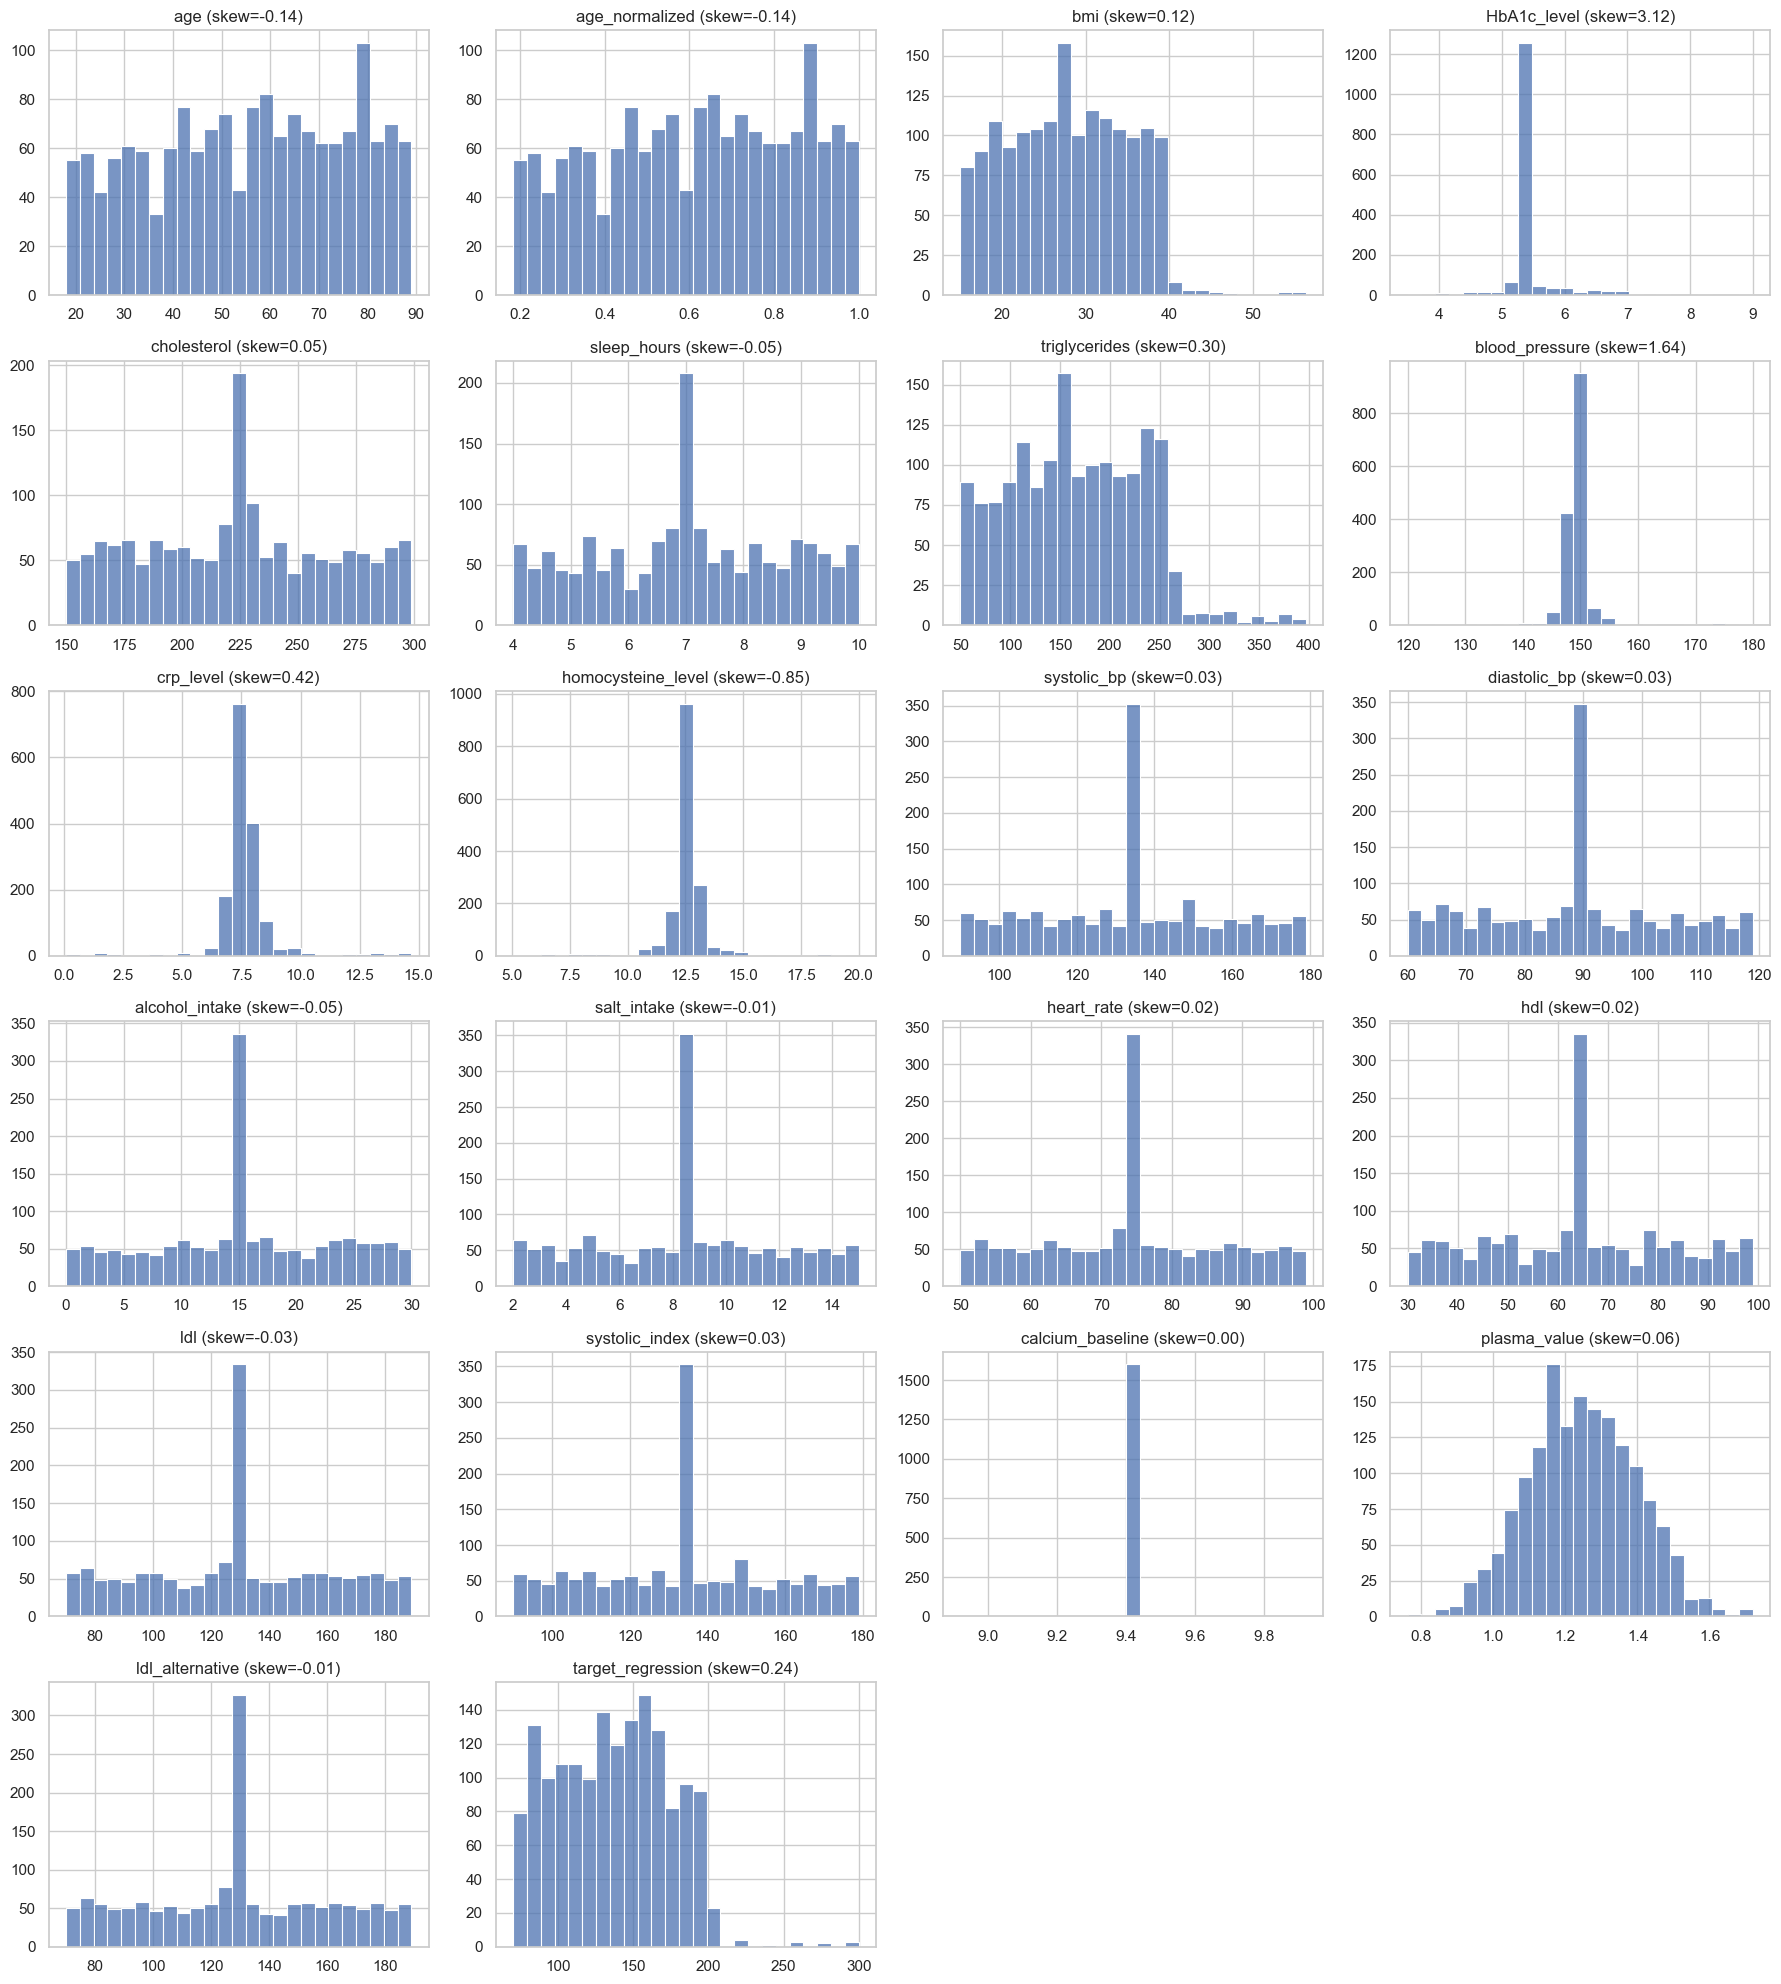

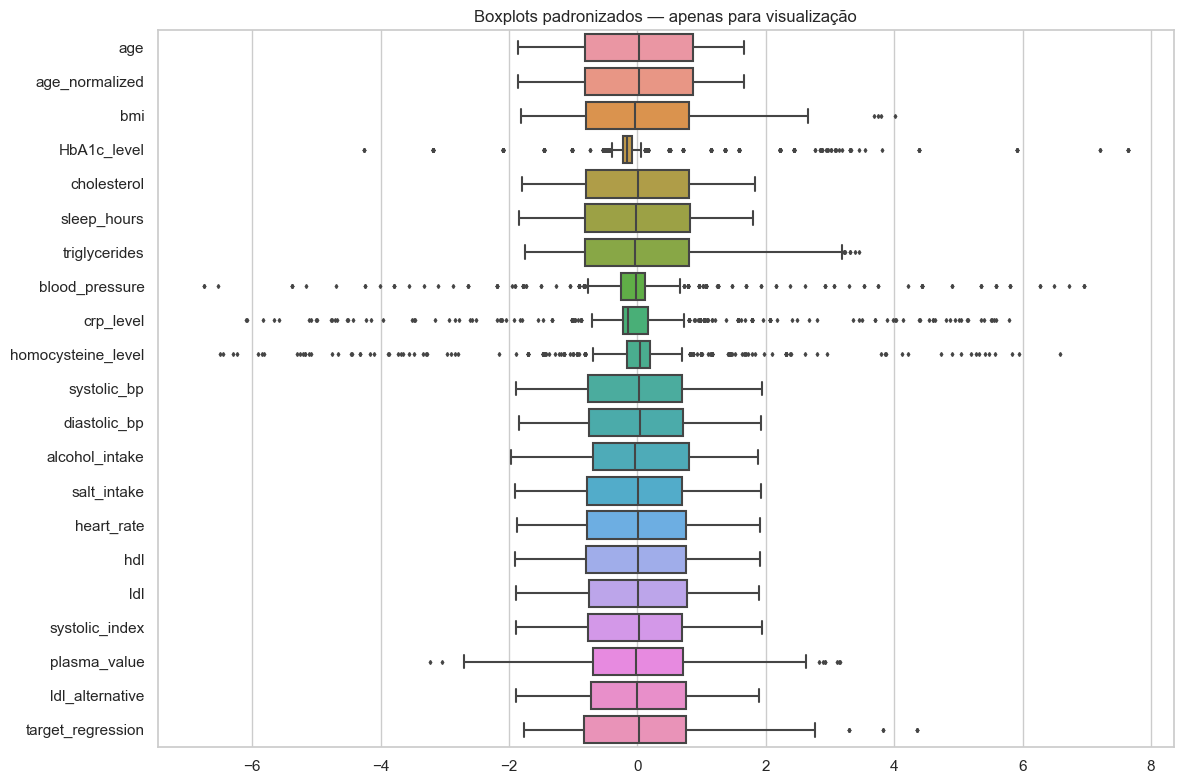

,"n fora de 1,5×IQR"
HbA1c_level,356
homocysteine_level,205
crp_level,178
blood_pressure,169
plasma_value,9
target_regression,8
triglycerides,7
bmi,4
heart_rate,0
ldl_alternative,0


In [4]:
fig,axes=plt.subplots(6,4,figsize=(18,20))
for ax,c in zip(axes.flat,num_cols):
    sns.histplot(df[c],bins=25,ax=ax)
    ax.set(title=f'{c} (skew={df[c].skew():.2f})',xlabel='',ylabel='')
for ax in list(axes.flat)[len(num_cols):]: ax.axis('off')
plt.tight_layout();plt.show()
nonconstant=[c for c in num_cols if df[c].nunique()>1]
z=(df[nonconstant]-df[nonconstant].mean())/df[nonconstant].std()
fig,ax=plt.subplots(figsize=(12,8))
sns.boxplot(data=z,orient='h',fliersize=2,ax=ax)
ax.set_title('Boxplots padronizados — apenas para visualização')
plt.tight_layout();plt.show()
def n_outliers(s):
    q1,q3=s.quantile([.25,.75]);iqr=q3-q1
    return int(((s<q1-1.5*iqr)|(s>q3+1.5*iqr)).sum())
display(pd.Series({c:n_outliers(df[c]) for c in num_cols},name='n fora de 1,5×IQR').sort_values(ascending=False).to_frame())

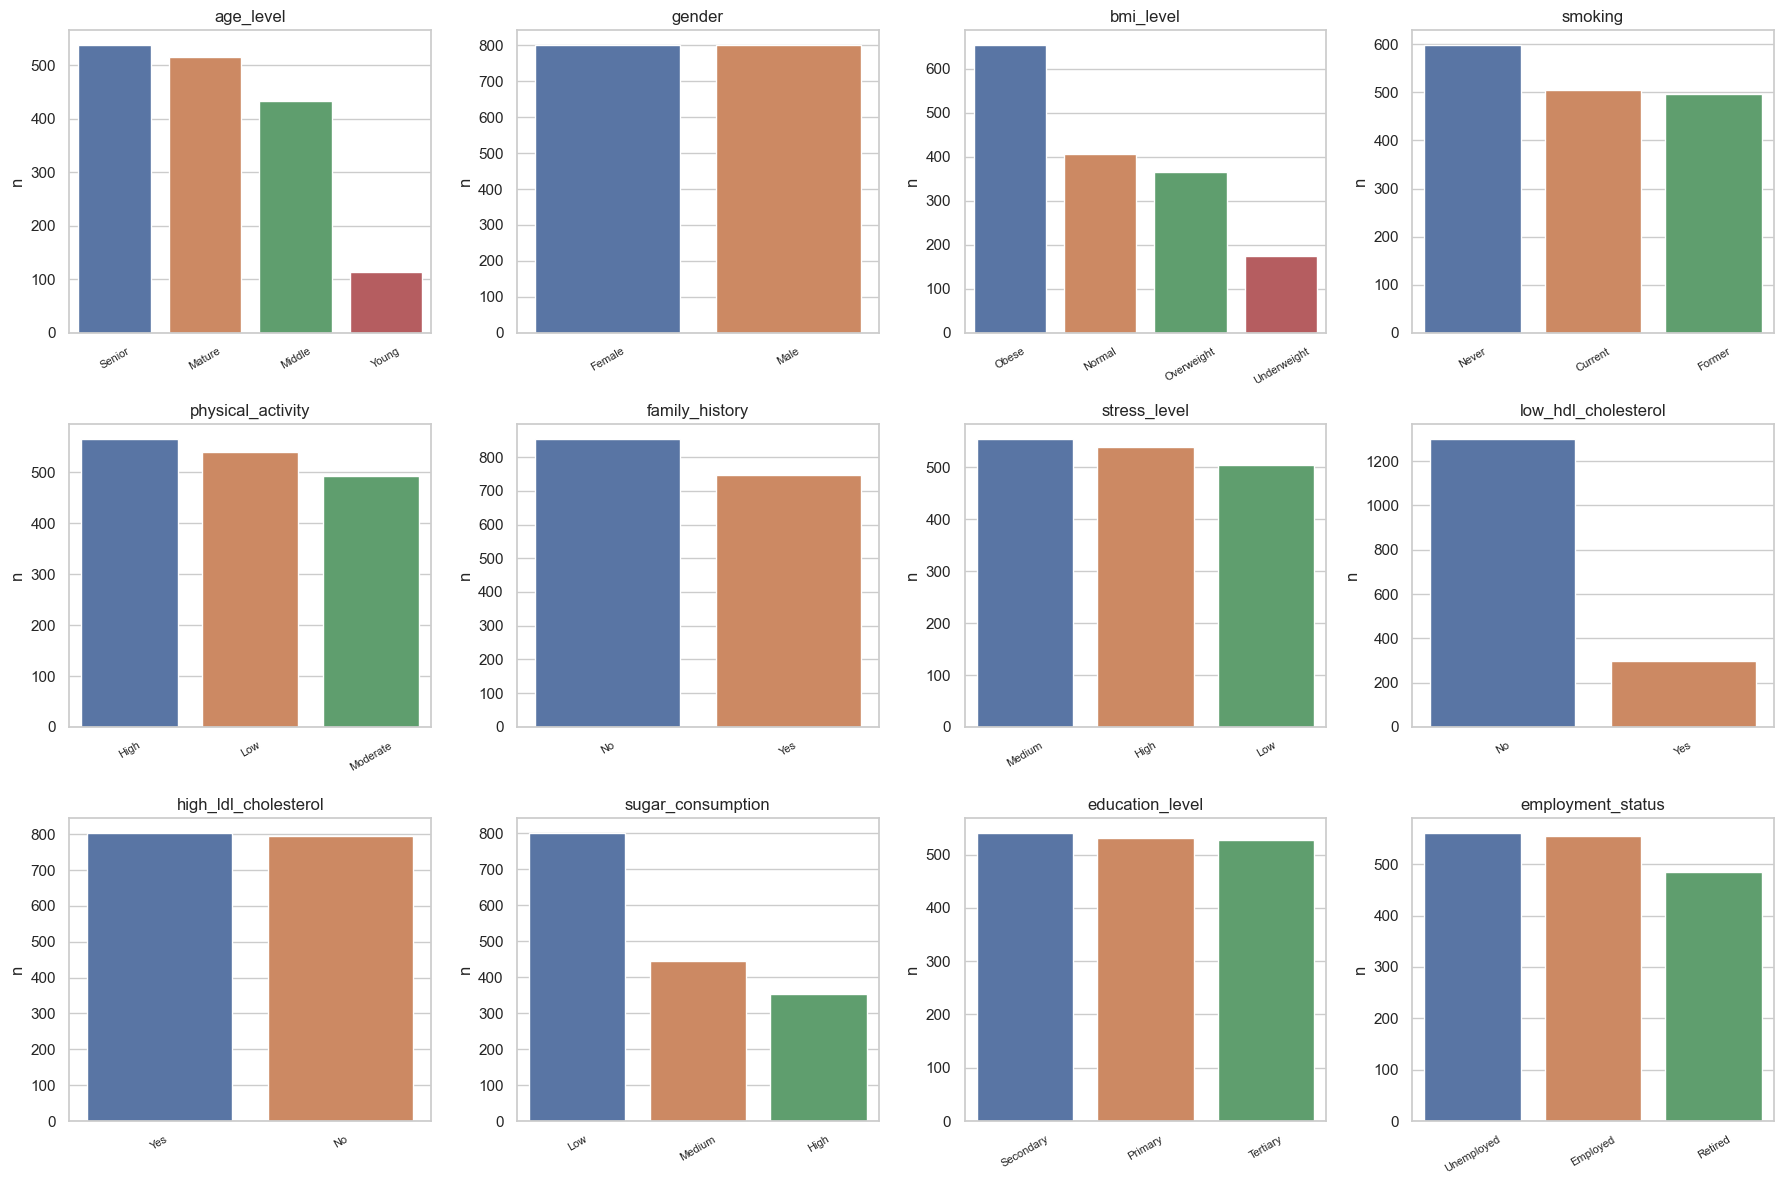

In [5]:
fig,axes=plt.subplots(3,4,figsize=(18,12))
for ax,c in zip(axes.flat,feat_cat):
    sns.countplot(data=df,x=c,order=df[c].value_counts().index,ax=ax)
    ax.set(title=c,xlabel='',ylabel='n');ax.tick_params(axis='x',rotation=30,labelsize=8)
for ax in list(axes.flat)[len(feat_cat):]:ax.axis('off')
plt.tight_layout();plt.show()

### 1.3 Análise bivariada com os dois alvos
Para regressão, calcula-se Pearson entre medidas quantitativas e o alvo. Para classificação,
comparam-se médias e dispersões por classe, F da ANOVA e associação entre categóricas por Cramér V/qui-quadrado.
Não se impõe uma escala numérica artificial aos diagnósticos ou ao estado profissional para calcular Pearson.

O F da ANOVA resume separação de médias, mas a homogeneidade de variâncias é questionável neste dataset:
não se interpreta um F baixo como prova de inutilidade. Os p-values categóricos são exploratórios,
ajustados por Holm; frequências esperadas pequenas limitam a aproximação do qui-quadrado.

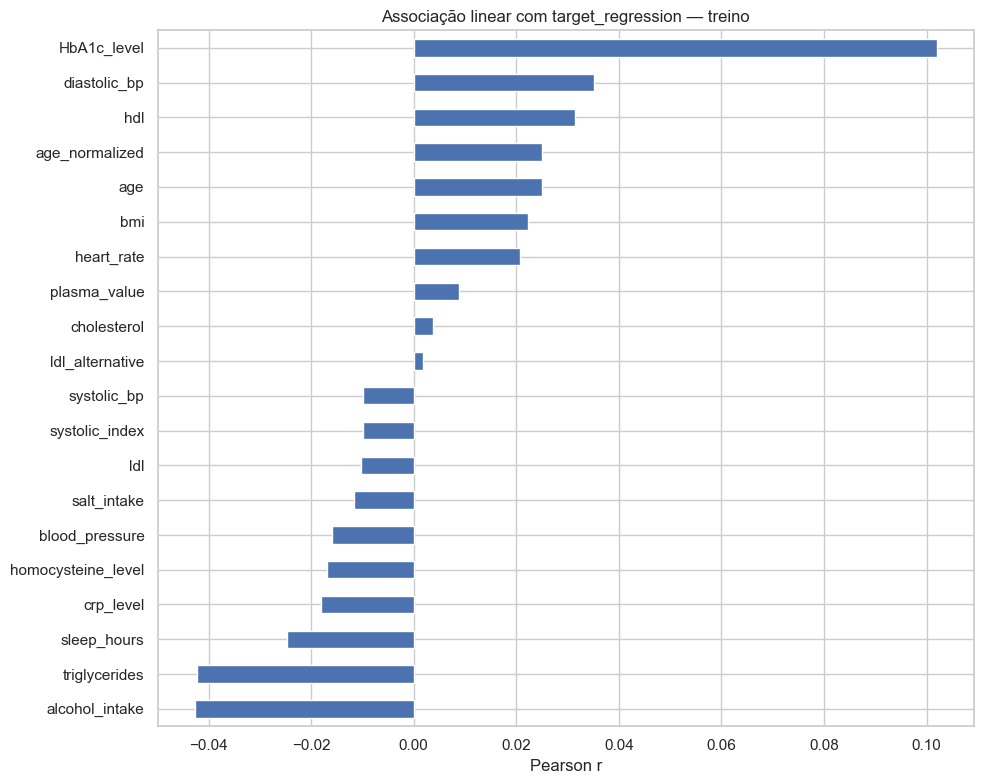

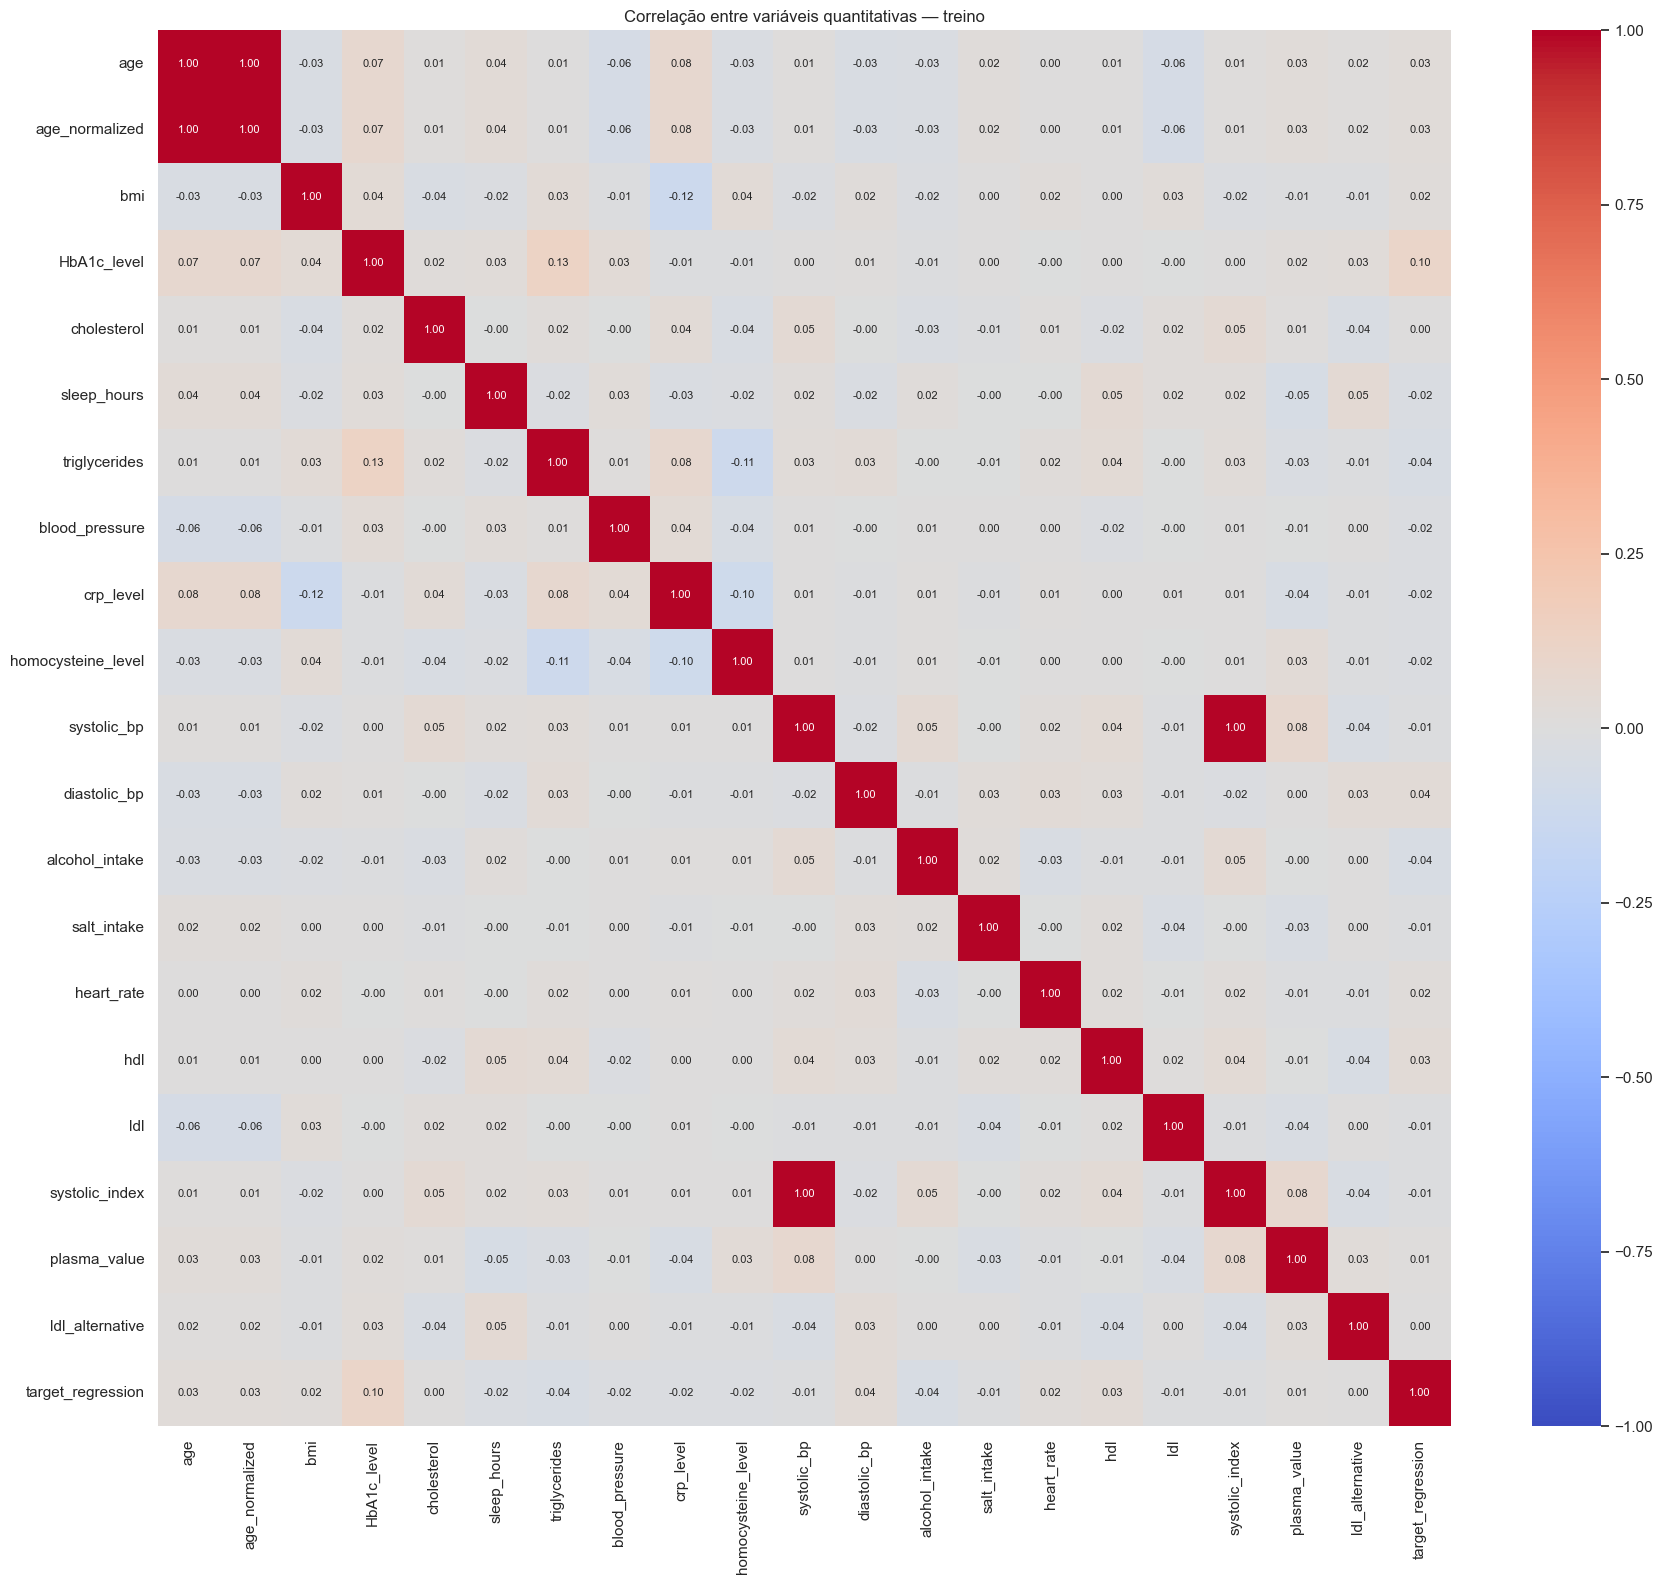

,F ANOVA (descritivo)
Preditor original,
HbA1c_level,711.209
triglycerides,75.267
age_normalized,14.707
age,14.707
bmi,7.190
blood_pressure,1.529
plasma_value,0.813
sleep_hours,0.619
crp_level,0.460


,Cramér V,p,mínimo esperado,p Holm
Preditor original,,,,
low_hdl_cholesterol,0.17040,0.00000,12.52062,0.00000
physical_activity,0.13466,0.00000,20.64438,0.00000
bmi_level,0.11674,0.00000,7.32812,0.00000
age_level,0.11553,0.00000,4.73187,0.00000
smoking,0.07489,0.00126,20.81188,0.01011
gender,0.07295,0.01415,33.45813,0.09908
family_history,0.05890,0.06234,31.23875,0.31171
education_level,0.05832,0.02790,22.11000,0.16739
high_ldl_cholesterol,0.05235,0.11169,33.33250,0.44677


,Preditor original,eta² descritivo (regressão)
9,sugar_consumption,0.0039
7,low_hdl_cholesterol,0.0039
4,physical_activity,0.0029
2,bmi_level,0.0026
11,employment_status,0.0020
3,smoking,0.0010
0,age_level,0.0008
5,family_history,0.0008
10,education_level,0.0005
8,high_ldl_cholesterol,0.0003


In [6]:
corr_reg_eda=df[feat_num].corrwith(df.target_regression).sort_values()
fig,ax=plt.subplots(figsize=(10,8));corr_reg_eda.plot.barh(ax=ax)
ax.set(title='Associação linear com target_regression — treino',xlabel='Pearson r')
plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(18,16))
sns.heatmap(df[feat_num+['target_regression']].corr(),cmap='coolwarm',center=0,vmin=-1,vmax=1,annot=True,fmt='.2f',annot_kws={'size':8},ax=ax)
ax.set_title('Correlação entre variáveis quantitativas — treino')
plt.tight_layout();plt.show()

anova_rows=[]
for c in feat_num:
    f,_=f_oneway(*(df.loc[df.target_class==cl,c] for cl in LABELS))
    anova_rows.append({'Preditor original':c,'F ANOVA (descritivo)':f})
anova=pd.DataFrame(anova_rows).set_index('Preditor original').sort_values('F ANOVA (descritivo)',ascending=False)
display(anova.head(10).round(3))
chi_rows=[]
for c in feat_cat:
    tab=pd.crosstab(df[c],df.target_class)
    stat,p,_,expected=chi2_contingency(tab)
    v=np.sqrt(stat/(tab.to_numpy().sum()*min(tab.shape[0]-1,tab.shape[1]-1)))
    chi_rows.append({'Preditor original':c,'Cramér V':v,'p':p,'mínimo esperado':expected.min()})
chi=pd.DataFrame(chi_rows).set_index('Preditor original')
chi['p Holm']=multipletests(chi['p'],method='holm')[1]
display(chi.sort_values('Cramér V',ascending=False).round(5))
eta_rows=[]
for c in feat_cat:
    groups=df.groupby(c).target_regression.agg(['count','mean'])
    eta=((groups['mean']-df.target_regression.mean())**2*groups['count']).sum()/((df.target_regression-df.target_regression.mean())**2).sum()
    eta_rows.append({'Preditor original':c,'eta² descritivo (regressão)':eta})
display(pd.DataFrame(eta_rows).sort_values('eta² descritivo (regressão)',ascending=False).round(4))

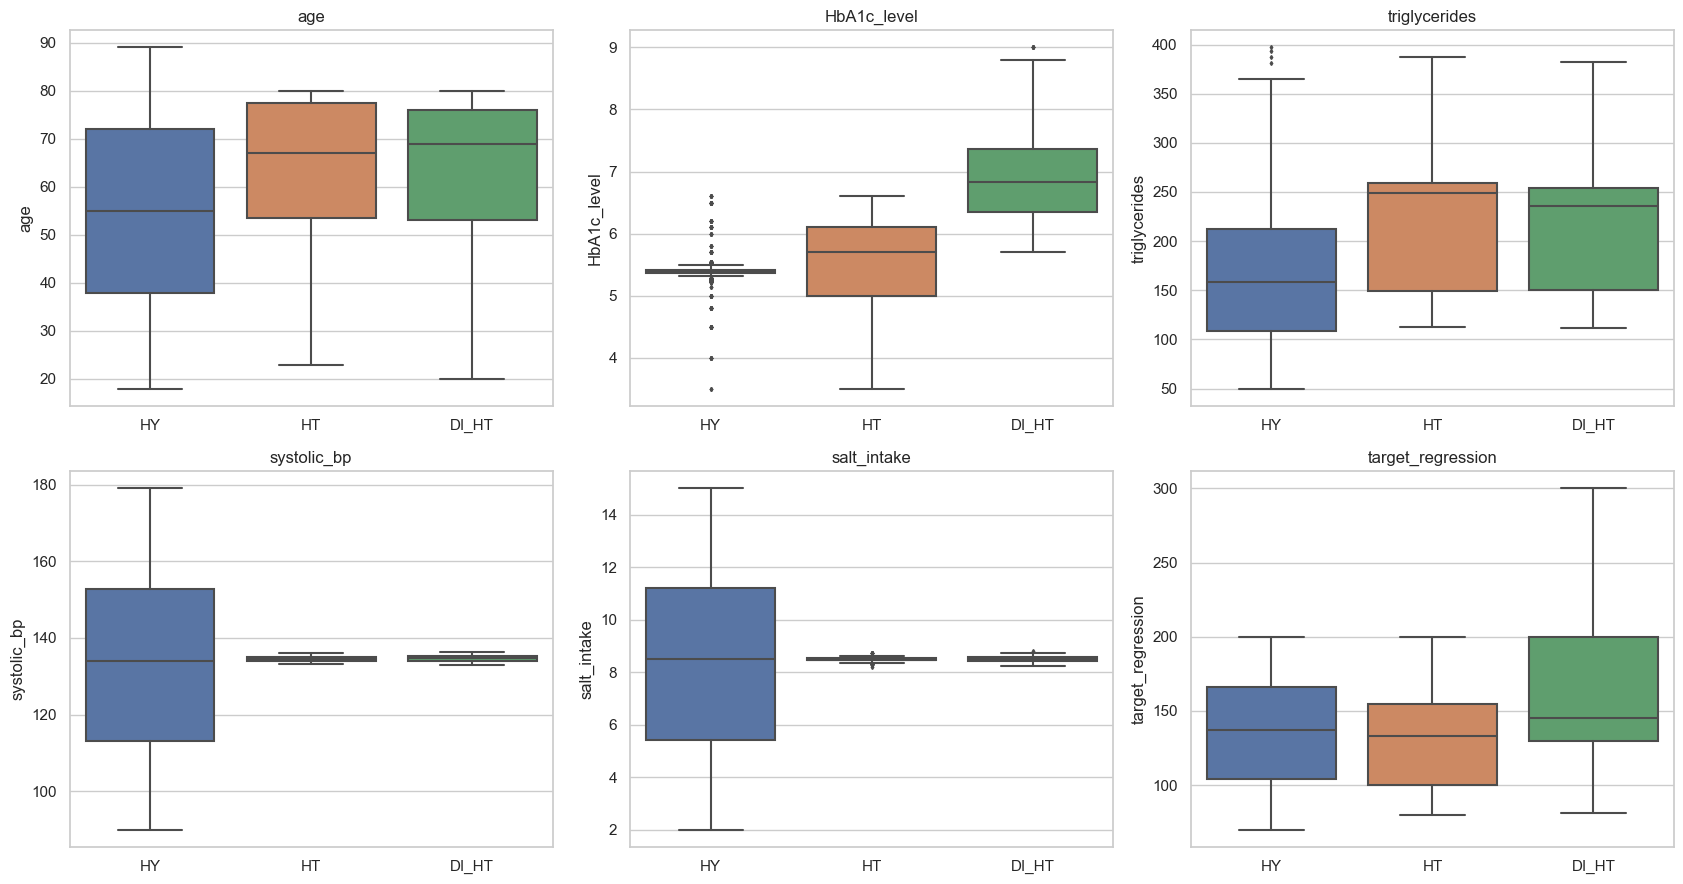

Média                        DP                
target_class             HY       HT    DI_HT      HY      HT   DI_HT
age                  54.714   63.934   63.642  20.482  14.802  15.361
age_normalized        0.606    0.712    0.709   0.235   0.170   0.177
bmi                  27.718   28.694   30.934   7.092   6.471   7.686
HbA1c_level           5.396    5.540    6.978   0.226   0.751   0.924
cholesterol         223.976  222.347  226.240  42.502  23.491  22.698
sleep_hours           7.042    6.983    7.257   1.705   0.921   0.967
triglycerides       160.402  228.410  222.278  63.414  63.841  69.297
blood_pressure      149.581  148.936  150.141   3.744   7.527   8.947
crp_level             7.580    7.462    7.516   1.065   1.989   2.539
homocysteine_level   12.479   12.425   12.400   1.028   1.722   2.124
systolic_bp         133.799  134.512  134.701  24.501   0.836   0.892
diastolic_bp         88.766   89.425   89.676  16.448   0.338   0.374
alcohol_intake       15.379   15.041   14.923   8.213   0.300   0.210
salt_intake           8.448    8.490    8.503   3.573   0.108   0.113
heart_rate           74.224   74.361   74.448  13.670   0.434   0.378
hdl                  64.401   64.640   64.480  19.079   0.545   0.667
ldl                 129.502  129.611  129.465  33.180   1.303   0.863
systolic_index      133.799  134.512  134.701  24.501   0.836   0.892
plasma_value          1.248    1.227    1.252   0.150   0.147   0.151
ldl_alternative     129.281  130.416  131.345  31.271  32.219  33.296

A maior associação linear quantitativa individual com o alvo contínuo é **HbA1c_level**, com |r|=0.102: o sinal linear marginal é fraco. Na classificação, observar também o DP: médias próximas com dispersões diferentes podem ser úteis ao QDA, embora não produzam um F elevado nem coeficientes importantes numa logística linear.

In [7]:
plot_features=['age','HbA1c_level','triglycerides','systolic_bp','salt_intake','target_regression']
fig,axes=plt.subplots(2,3,figsize=(17,9))
for ax,c in zip(axes.flat,plot_features):
    sns.boxplot(data=df,x='target_class',y=c,order=LABELS,fliersize=2,ax=ax)
    ax.set(title=c,xlabel='')
plt.tight_layout();plt.show()
stats_by_cls=pd.concat({'Média':df.groupby('target_class')[feat_num].mean().reindex(LABELS).T,
                        'DP':df.groupby('target_class')[feat_num].std().reindex(LABELS).T},axis=1)
display(stats_by_cls.round(3))
display(Markdown(f'A maior associação linear quantitativa individual com o alvo contínuo é '
    f'**{corr_reg_eda.abs().idxmax()}**, com |r|={corr_reg_eda.abs().max():.3f}: o sinal linear marginal é fraco. '
    'Na classificação, observar também o DP: médias próximas com dispersões diferentes podem ser úteis '
    'ao QDA, embora não produzam um F elevado nem coeficientes importantes numa logística linear.'))

### 1.4 Limpeza, redundâncias e codificação
Removem-se `calcium_baseline`, por ser constante, `systolic_index`, por replicar a pressão
sistólica, e `age_normalized`, por ser um reescalamento quase exato de `age`.
Usam-se também `age` e `bmi` em vez das suas categorizações `age_level` e `bmi_level`,
privilegiando uma representação parcimoniosa das medidas originais. As categorias derivadas
poderiam ser estudadas como bases não lineares noutro modelo.

A auditoria quantitativa mostra que `ldl_alternative` não replica linearmente `ldl`.
Mantém-se como preditor candidato, juntamente com `plasma_value`, `stress_level` e
`sugar_consumption`; a regularização avalia a sua contribuição condicional.

As categorias descritas no enunciado são representadas por one-hot encoding com vocabulário
fixo. Esta codificação determinística preserva a natureza nominal de variáveis como
`smoking` e `employment_status`. O escalonamento e a seleção supervisionada são ajustados
**dentro de cada fold**, usando exclusivamente o respetivo treino.

In [8]:
print('Constantes:',df.columns[df.nunique()==1].tolist())
print('systolic_index igual a systolic_bp:',np.allclose(df.systolic_index,df.systolic_bp))
print('Correlação age/age_normalized:',df.age.corr(df.age_normalized))
print('Correlação ldl/ldl_alternative:',df.ldl.corr(df.ldl_alternative))
display(df.groupby('age_level').age.agg(['min','max']))
display(df.groupby('bmi_level').bmi.agg(['min','max']))
DROP=['age_normalized','systolic_index','calcium_baseline','age_level','bmi_level']
CATEGORIES={
 'gender':['Female','Male'],'smoking':['Current','Former','Never'],
 'physical_activity':['High','Low','Moderate'],'family_history':['No','Yes'],
 'stress_level':['High','Low','Medium'],'low_hdl_cholesterol':['No','Yes'],
 'high_ldl_cholesterol':['No','Yes'],'sugar_consumption':['High','Low','Medium'],
 'education_level':['Primary','Secondary','Tertiary'],
 'employment_status':['Employed','Retired','Unemployed']}
RAW_FEATURES=[c for c in df if c not in DROP+['target_class','target_regression']]
def encode(frame):
    out=frame[RAW_FEATURES].copy()
    for c,levels in CATEGORIES.items():
        if not out[c].isin(levels).all():raise ValueError(f'Categoria desconhecida ou falta em {c}')
        out[c]=pd.Categorical(out[c],categories=levels)
    return pd.get_dummies(out,columns=list(CATEGORIES),drop_first=True,dtype=float)
X_all=encode(df)
X_reserved=encode(df_test).reindex(columns=X_all.columns)
y_reg=df.target_regression.copy();y_cls=df.target_class.copy()
yr_reserved=df_test.target_regression.copy();yc_reserved=df_test.target_class.copy()
assert X_all.notna().all().all() and X_reserved.notna().all().all()
N_FEATURES=X_all.shape[1]
print('Preditores originais mantidos:',len(RAW_FEATURES),'| Colunas após encoding:',N_FEATURES)
display(pd.Series(X_all.columns,name='Colunas disponíveis').to_frame())
vif_input=sm.add_constant(X_all)
vif=pd.Series({c:variance_inflation_factor(vif_input.to_numpy(),i+1) for i,c in enumerate(X_all)},name='VIF').sort_values(ascending=False)
display(vif.head(12).round(3).to_frame())

Constantes: ['calcium_baseline']
systolic_index igual a systolic_bp: True
Correlação age/age_normalized: 0.9999999999990359
Correlação ldl/ldl_alternative: 0.004690362681299479
Preditores originais mantidos: 28 | Colunas após encoding: 34


,min,max
age_level,,
Mature,46,67
Middle,24,45
Senior,68,89
Young,18,23


,min,max
bmi_level,,
Normal,18.5,24.991591
Obese,30.0,56.390000
Overweight,25.0,29.980000
Underweight,15.0,18.496478


,Colunas disponíveis
0,age
1,bmi
2,HbA1c_level
3,cholesterol
4,sleep_hours
5,triglycerides
6,blood_pressure
7,crp_level
8,homocysteine_level
9,systolic_bp


,VIF
high_ldl_cholesterol_Yes,2.660
ldl,2.645
sugar_consumption_Low,1.854
sugar_consumption_Medium,1.755
smoking_Former,1.510
low_hdl_cholesterol_Yes,1.411
smoking_Never,1.404
education_level_Tertiary,1.389
education_level_Secondary,1.377
stress_level_Low,1.367


#### Auditoria quantitativa de redundância
Comparam-se igualdade, correlação e resíduo máximo de um ajuste afim no treino.
O resíduo permite distinguir uma réplica exata, um reescalamento arredondado e duas
medições sem equivalência linear. A tabela fundamenta as decisões de preparação.

In [9]:
redundancy_rows=[]
for a,b in [('age','age_normalized'),('systolic_bp','systolic_index'),('ldl','ldl_alternative')]:
    slope,intercept=np.polyfit(df[a],df[b],1)
    residual=np.abs(df[b]-(slope*df[a]+intercept))
    redundancy_rows.append({'Coluna A':a,'Coluna B':b,
        'Iguais (tolerância 1e-10)':np.allclose(df[a],df[b],rtol=0,atol=1e-10),
        'Pearson r':df[a].corr(df[b]),'Declive afim':slope,
        'Intercepto afim':intercept,'Máximo |resíduo afim|':residual.max()})
redundancy_audit=pd.DataFrame(redundancy_rows)
display(redundancy_audit.round(8))
display(pd.DataFrame({'n valores distintos':[df.calcium_baseline.nunique()],
                     'valor':[df.calcium_baseline.iloc[0]],
                     'DP':[df.calcium_baseline.std()]} ,index=['calcium_baseline']))
display(Markdown(f'`systolic_index` replica a pressão sistólica; `age_normalized` é quase um '
    'reescalamento afim, com pequeno erro de arredondamento. '
    f'Já `ldl_alternative` tem r={df.ldl.corr(df.ldl_alternative):.5f} com `ldl` e resíduo afim '
    f'máximo={redundancy_audit.iloc[2]["Máximo |resíduo afim|"]:.3f}: **não é uma cópia linear**. '
    f'`plasma_value` tem {df.plasma_value.nunique()} valores distintos em {len(df)} pacientes de treino '
    f'e r={df.plasma_value.corr(df.target_regression):.5f} com o alvo contínuo. '
    'Isto sugere pouca associação linear marginal com esse alvo, mas não demonstra ruído nem '
    'ausência de associação com as classes. Mantêm-se ambas as variáveis nos modelos completos.'))

,Coluna A,Coluna B,Iguais (tolerância 1e-10),Pearson r,Declive afim,Intercepto afim,Máximo |resíduo afim|
0,age,age_normalized,False,1.00000,0.011494,-0.022989,5.500000e-07
1,systolic_bp,systolic_index,True,1.00000,1.000000,0.000000,0.000000e+00
2,ldl,ldl_alternative,False,0.00469,0.004675,128.826498,5.974810e+01


,n valores distintos,valor,DP
calcium_baseline,1,9.42,6.574575e-14


`systolic_index` replica a pressão sistólica; `age_normalized` é quase um reescalamento afim, com pequeno erro de arredondamento. Já `ldl_alternative` tem r=0.00469 com `ldl` e resíduo afim máximo=59.748: **não é uma cópia linear**. `plasma_value` tem 1600 valores distintos em 1600 pacientes de treino e r=0.00881 com o alvo contínuo. Isto sugere pouca associação linear marginal com esse alvo, mas não demonstra ruído nem ausência de associação com as classes. Mantêm-se ambas as variáveis nos modelos completos.

**Interpretação:** o VIF avalia a dependência linear de cada preditor em relação aos restantes.
O conjunto após preparação constitui a referência para comparar os subconjuntos L1.
Os valores extremos permanecem na amostra, pois podem representar perfis clínicos relevantes;
a eliminação de preditores combina evidência de redundância e avaliação preditiva.

### 1.5 Relações após encoding: preditores e os dois targets
A matriz seguinte apresenta as relações entre os preditores e a associação com os dois alvos.
Os **28 preditores originais retidos** são codificados com one-hot; na EDA mostram-se **todas as
categorias**, para não esconder as categorias de referência. Esta matriz descritiva não substitui
a matriz dos modelos: estes continuam a usar `drop_first=True`, evitando a dependência exata
introduzida pela soma dos indicadores de cada variável. As colunas retiradas por redundância
ou parcimónia continuam documentadas nas secções 1.3–1.4.

- Contínua/contínua: Pearson descreve a associação linear.
- Indicador 0/1/contínua: Pearson equivale à correlação ponto-bisserial e compara a presença da categoria com a sua ausência.
- Indicador 0/1/indicador 0/1: Pearson é o coeficiente phi.

Para `target_class`, criam-se **três indicadores**, um por diagnóstico: cada coluna compara
essa classe com todas as restantes. Não se codifica HY/HT/DI_HT como 0/1/2: isso imporia uma
ordem e distâncias sem fundamento. O sinal indica associação com a **presença da categoria**,
não gravidade clínica. A prevalência das classes afeta estes coeficientes, que não substituem
a ANOVA/Cramér V da análise global nem detetam todas as relações não lineares ou de dispersão.

**Escalonamento:** não é necessário padronizar antes de Pearson: centrar e dividir por um desvio
positivo não altera r. Encoding representa categorias; escalonamento altera unidades. Nos modelos,
o StandardScaler continua a ser ajustado dentro de cada fold, incluindo os indicadores para
uniformizar a escala da penalização. Esta EDA usa exclusivamente o treino e não define novas
seleções de preditores ou de C.

EDA: 1600 pacientes; 44 colunas com todas as categorias. Modelos: 34 colunas com categoria de referência omitida.


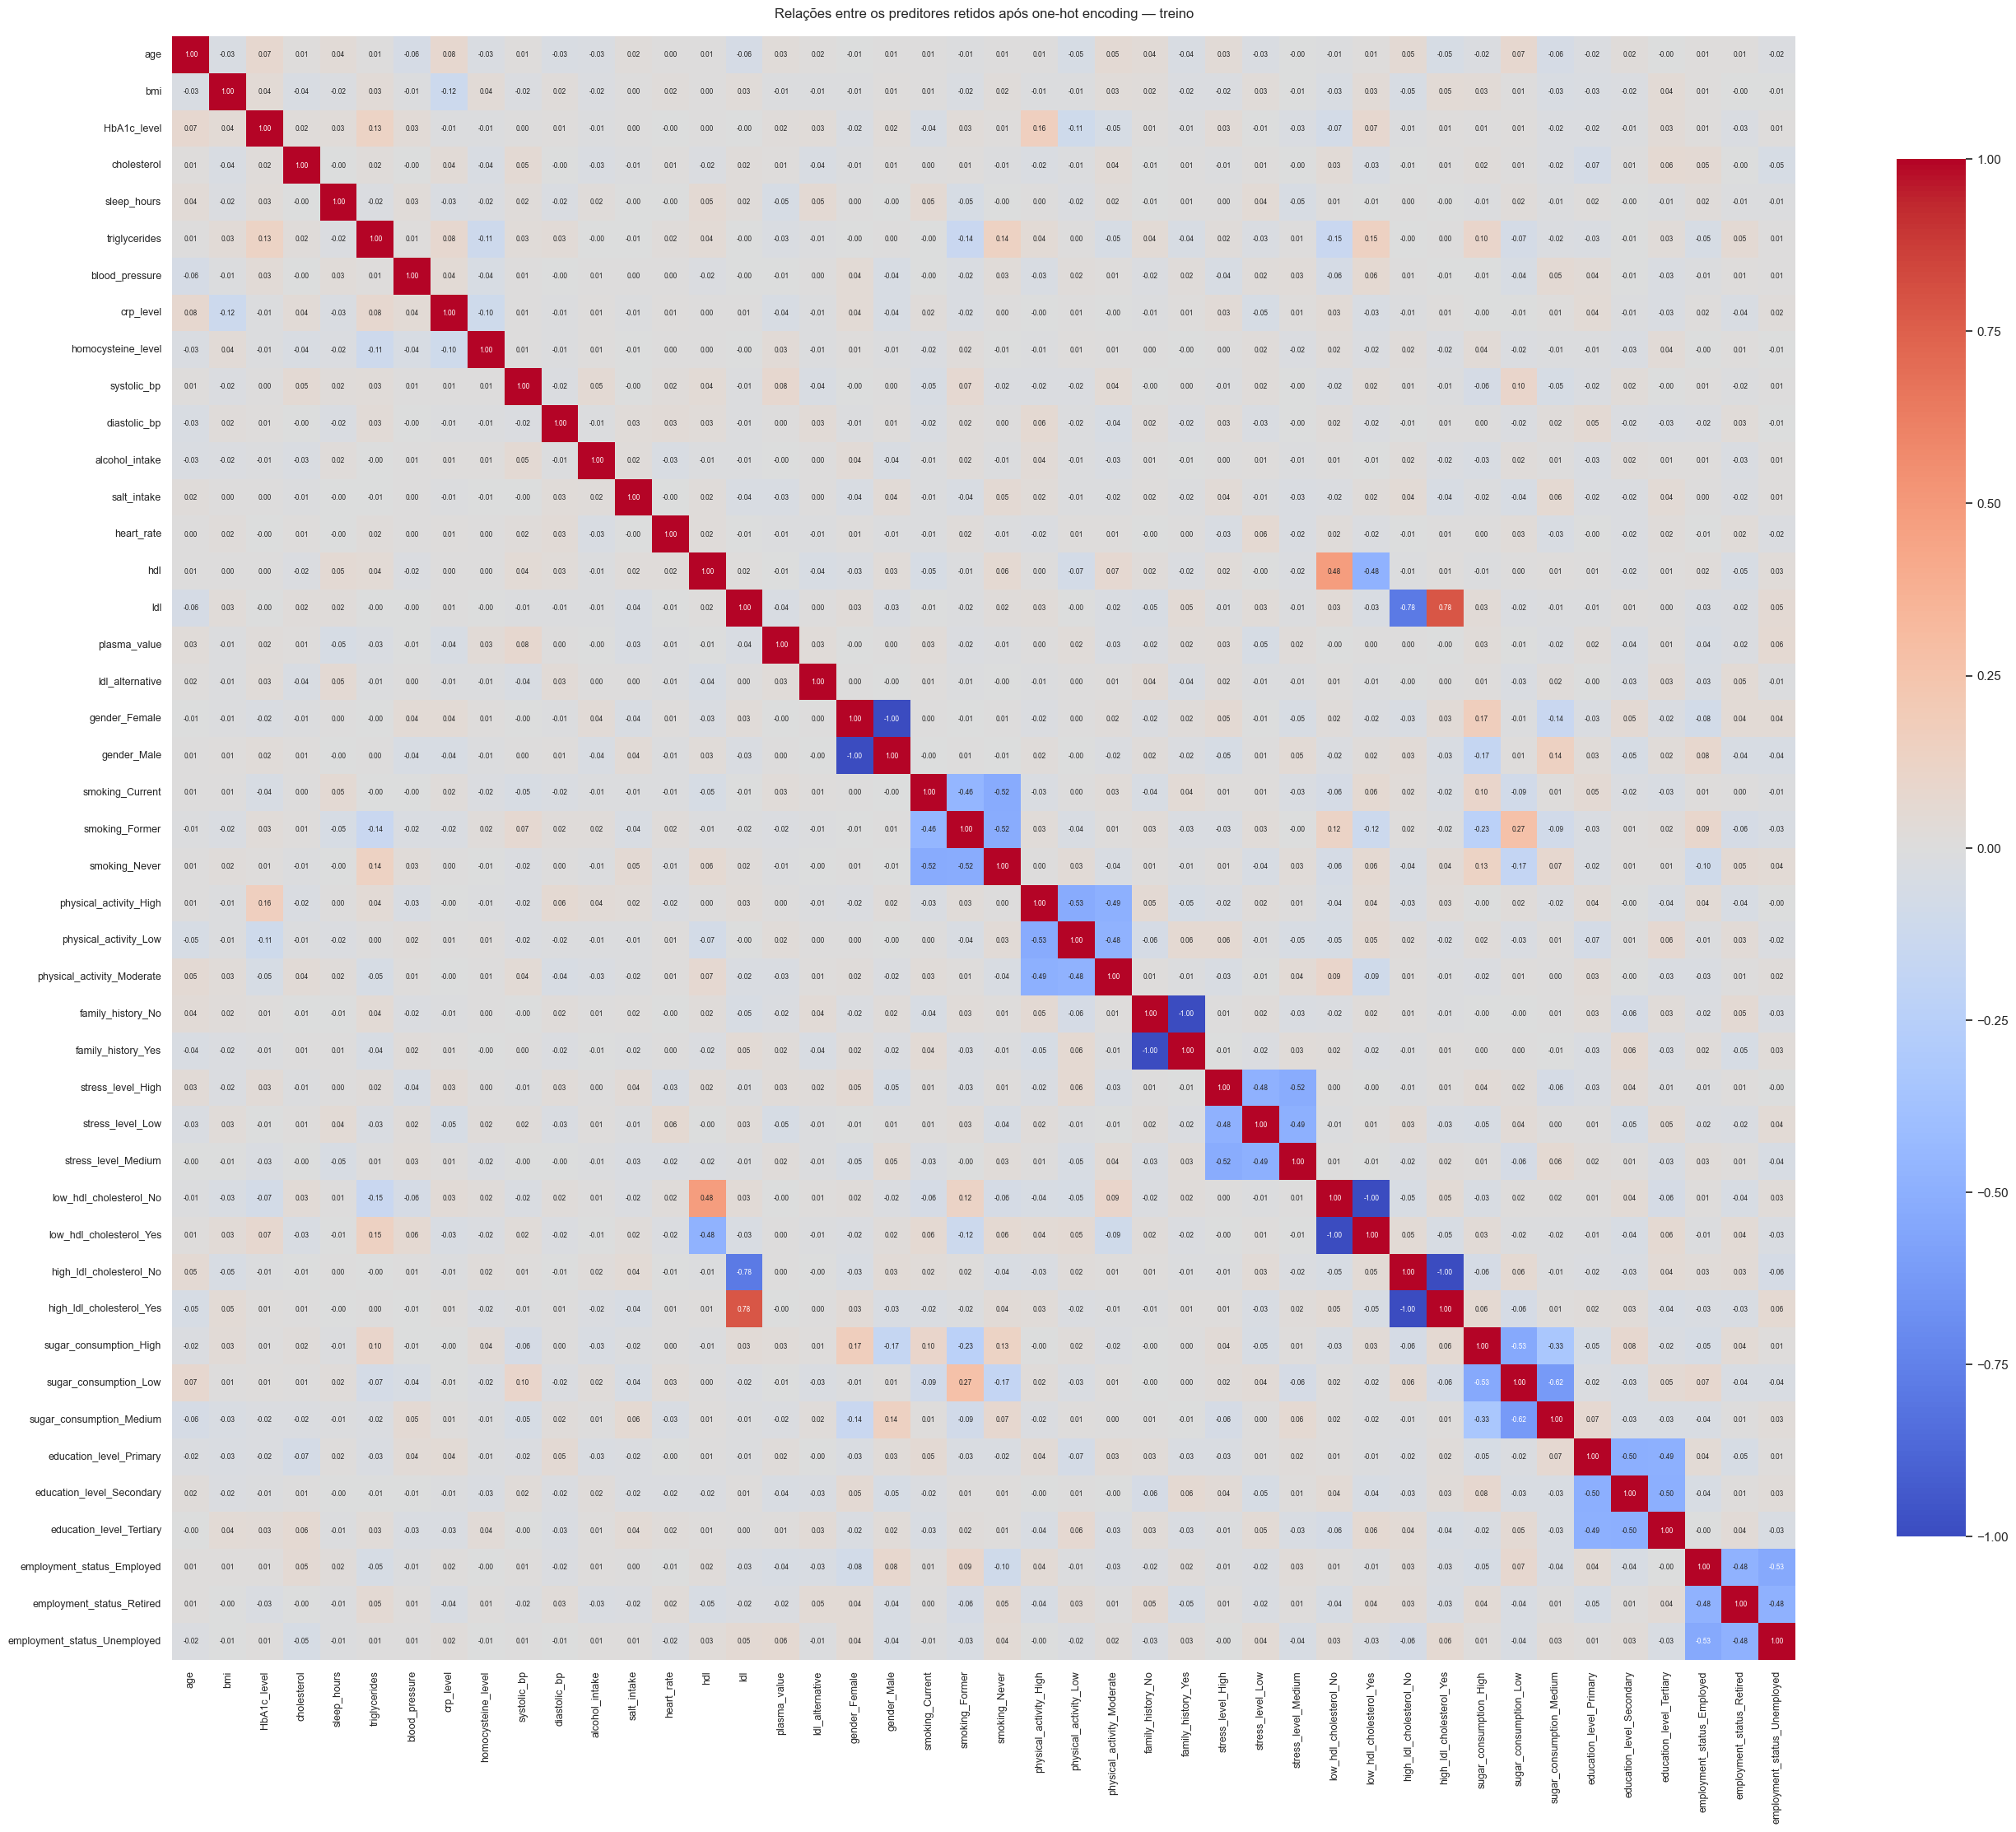

,Preditor A,Preditor B,Pearson r,|r|
557,ldl,high_ldl_cholesterol_No,-0.7828,0.7828
558,ldl,high_ldl_cholesterol_Yes,0.7828,0.7828
528,hdl,low_hdl_cholesterol_Yes,-0.4776,0.4776
527,hdl,low_hdl_cholesterol_No,0.4776,0.4776
703,smoking_Former,sugar_consumption_Low,0.2733,0.2733
702,smoking_Former,sugar_consumption_High,-0.2334,0.2334
724,smoking_Never,sugar_consumption_Low,-0.1727,0.1727
636,gender_Female,sugar_consumption_High,0.1666,0.1666
660,gender_Male,sugar_consumption_High,-0.1666,0.1666
105,HbA1c_level,physical_activity_High,0.1571,0.1571


As relações entre categorias da mesma variável incluem dependências criadas pelo próprio encoding. A tabela exclui esses pares e mostra as maiores associações entre variáveis originais distintas. A interpretação combina estas associações marginais com a auditoria de redundância e a contribuição conjunta avaliada nos modelos.

In [10]:
# Matriz apenas descritiva; nunca é passada aos modelos.
eda_frame=df[RAW_FEATURES].copy()
for c,levels in CATEGORIES.items():
    eda_frame[c]=pd.Categorical(eda_frame[c],categories=levels)
eda_encoded=pd.get_dummies(eda_frame,columns=list(CATEGORIES),drop_first=False,dtype=float)
eda_encoded=eda_encoded.loc[:,eda_encoded.nunique()>1]
encoded_corr=eda_encoded.corr()
assert eda_encoded.index.equals(df.index)
assert not set(eda_encoded.index)&set(test_idx)
assert not {'target_class','target_regression'}&set(eda_encoded.columns)
print('EDA:',len(eda_encoded),'pacientes;',eda_encoded.shape[1],
      'colunas com todas as categorias. Modelos:',N_FEATURES,'colunas com categoria de referência omitida.')
fig,ax=plt.subplots(figsize=(27,25))
sns.heatmap(encoded_corr,cmap='coolwarm',vmin=-1,vmax=1,center=0,square=True,
            annot=True,fmt='.2f',annot_kws={'size':6},
            xticklabels=True,yticklabels=True,ax=ax,cbar_kws={'shrink':.7})
ax.tick_params(axis='both',labelsize=9)
ax.set_title('Relações entre os preditores retidos após one-hot encoding — treino',pad=16)
plt.tight_layout();plt.show()

def eda_origin(col):
    matches=[c for c in CATEGORIES if col.startswith(c+'_')]
    return max(matches,key=len) if matches else col
pair_rows=[]
for i,a in enumerate(encoded_corr.columns):
    for b in encoded_corr.columns[i+1:]:
        # Indicadores da mesma variável têm exclusão mútua por construção.
        if eda_origin(a)!=eda_origin(b):
            pair_rows.append({'Preditor A':a,'Preditor B':b,'Pearson r':encoded_corr.loc[a,b]})
encoded_pairs=pd.DataFrame(pair_rows)
encoded_pairs['|r|']=encoded_pairs['Pearson r'].abs()
display(encoded_pairs.sort_values('|r|',ascending=False).head(12).round(4))
display(Markdown('As relações entre categorias da mesma variável incluem dependências '
    'criadas pelo próprio encoding. A tabela exclui esses pares e mostra as maiores associações '
    'entre variáveis originais distintas. A interpretação combina estas associações marginais '
    'com a auditoria de redundância e a contribuição conjunta avaliada nos modelos.'))

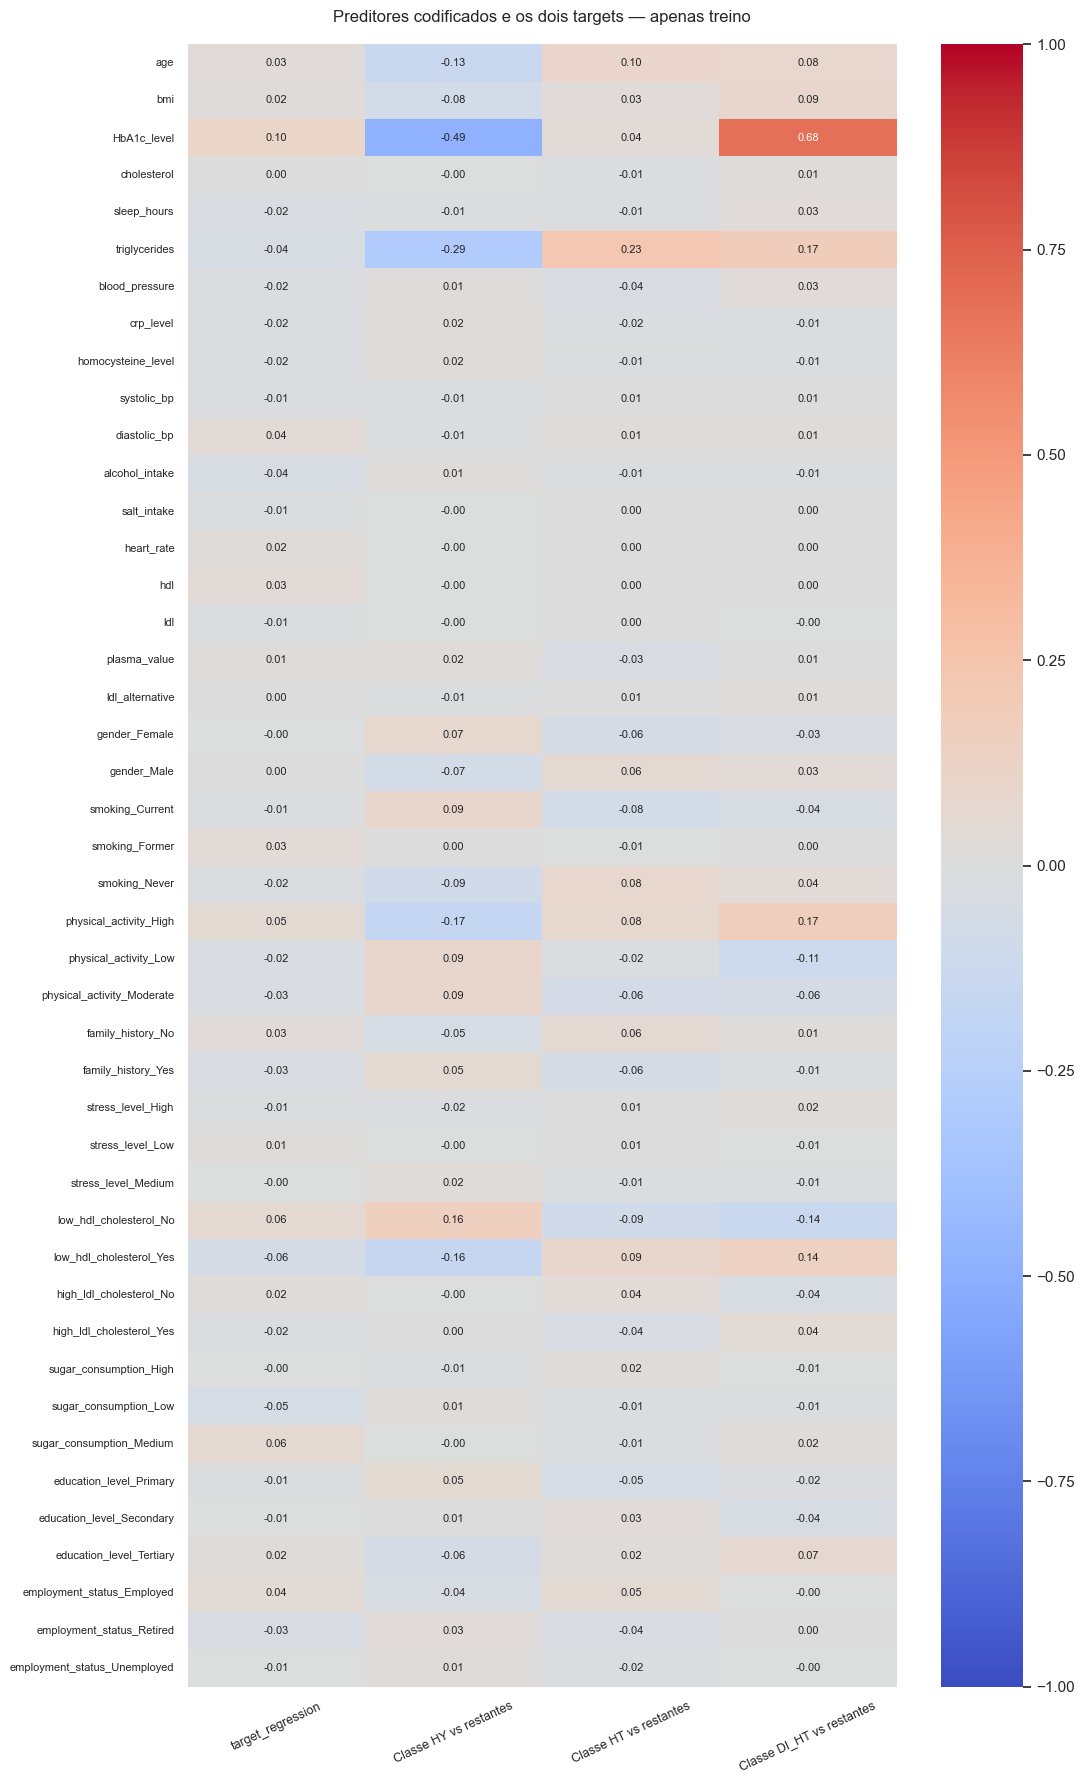

,target_regression,Classe HY vs restantes,Classe HT vs restantes,Classe DI_HT vs restantes
age,0.02509,-0.13446,0.10126,0.08318
bmi,0.02224,-0.08081,0.02714,0.08897
HbA1c_level,0.10201,-0.48708,0.03709,0.68255
cholesterol,0.00375,-0.00016,-0.00977,0.01154
sleep_hours,-0.02467,-0.01033,-0.00967,0.02656
triglycerides,-0.04219,-0.29315,0.22707,0.17405
blood_pressure,-0.01584,0.00910,-0.03542,0.02740
crp_level,-0.01807,0.02302,-0.02164,-0.00927
homocysteine_level,-0.01682,0.01679,-0.01015,-0.01327
systolic_bp,-0.00985,-0.01017,0.00670,0.00740


**Maiores |r| com target_regression:** HbA1c_level: r=0.102; low_hdl_cholesterol_No: r=0.062; low_hdl_cholesterol_Yes: r=-0.062.

**Maiores |r| com Classe HY vs restantes:** HbA1c_level: r=-0.487; triglycerides: r=-0.293; physical_activity_High: r=-0.171.

**Maiores |r| com Classe HT vs restantes:** triglycerides: r=0.227; age: r=0.101; low_hdl_cholesterol_No: r=-0.090.

**Maiores |r| com Classe DI_HT vs restantes:** HbA1c_level: r=0.683; triglycerides: r=0.174; physical_activity_High: r=0.165.

**Ligação à análise anterior.** O alvo contínuo mantém associações marginais fracas; a comparação das regressões na secção 2 verifica se essas associações produzem ganho preditivo. As três colunas de diagnóstico tornam visíveis associações diferentes consoante a classe. ANOVA e Cramér V da secção 1.3 resumem relações globais por variável original, enquanto esta tabela detalha as categorias. Diferenças de dispersão podem continuar a ser informativas mesmo com r pequeno, como ilustrado pelos boxplots e pelo QDA. Nenhum dos targets, nem os seus indicadores, entra como preditor nos modelos.

In [11]:
class_indicators=pd.DataFrame({f'Classe {cl} vs restantes':(df.target_class==cl).astype(float)
                               for cl in LABELS},index=df.index)
targets_eda=pd.concat([df[['target_regression']],class_indicators],axis=1)
target_associations=pd.DataFrame({t:eda_encoded.corrwith(targets_eda[t]) for t in targets_eda})
assert np.isfinite(target_associations.to_numpy()).all()
fig,ax=plt.subplots(figsize=(11,18))
sns.heatmap(target_associations,cmap='coolwarm',vmin=-1,vmax=1,center=0,annot=True,
            fmt='.2f',annot_kws={'size':8},ax=ax)
ax.set_title('Preditores codificados e os dois targets — apenas treino',pad=16)
ax.tick_params(axis='x',rotation=25,labelsize=9)
ax.tick_params(axis='y',labelsize=8)
plt.tight_layout();plt.show()
display(target_associations.round(5))
for t in targets_eda:
    top=target_associations[t].abs().nlargest(3).index
    text='; '.join(f'{c}: r={target_associations.loc[c,t]:.3f}' for c in top)
    display(Markdown(f'**Maiores |r| com {t}:** {text}.'))
display(Markdown('**Ligação à análise anterior.** O alvo contínuo mantém associações marginais '
    'fracas; a comparação das regressões na secção 2 verifica se essas associações produzem '
    'ganho preditivo. As três colunas de diagnóstico tornam visíveis associações diferentes '
    'consoante a classe. ANOVA e Cramér V da secção 1.3 resumem relações globais por variável '
    'original, enquanto esta tabela detalha as categorias. Diferenças de dispersão podem '
    'continuar a ser informativas mesmo com r pequeno, como ilustrado pelos boxplots e pelo QDA. '
    'Nenhum dos targets, nem os seus indicadores, entra como preditor nos modelos.'))

## 2. Regressão — previsão de `target_regression`
### 2.1 Comparação de todas as regressões simples
Testa-se uma coluna de cada vez, incluindo indicadores binários. O critério de escolha é o maior
**R² médio em CV5 no treino**; MAE e RMSE complementam a interpretação. O baseline é realmente
avaliado nos mesmos folds: o seu R² de CV não é colocado artificialmente em zero.

O ranking por correlação e o ranking por CV podem diferir: Pearson descreve o ajuste marginal,
enquanto CV mede previsões em folds não usados no ajuste. Nenhuma das tabelas abaixo consulta o teste final.

In [12]:
reg_cv=KFold(5,shuffle=True,random_state=SEED)
reg_scoring={'R2':'r2','MAE':'neg_mean_absolute_error','MSE':'neg_mean_squared_error'}
def reg_cv_row(name,model):
    r=cross_validate(model,X_all,y_reg,cv=reg_cv,scoring=reg_scoring,error_score='raise')
    return {'modelo':name,'R2 CV':r['test_R2'].mean(),'DP R2 entre folds':r['test_R2'].std(ddof=1),
            'MAE CV':-r['test_MAE'].mean(),'RMSE CV':np.sqrt(-r['test_MSE']).mean()}
baseline_reg=DummyRegressor(strategy='mean')
reg_baseline_cv=reg_cv_row('Baseline (média)',baseline_reg)
simple_rows=[]
for c in X_all:
    scores=cross_validate(make_pipeline(StandardScaler(),LinearRegression()),X_all[[c]],y_reg,cv=reg_cv,scoring=reg_scoring)
    simple_rows.append({'feature':c,'Pearson |r| treino':abs(X_all[c].corr(y_reg)),
        'R2 CV':scores['test_R2'].mean(),'DP R2 entre folds':scores['test_R2'].std(ddof=1),
        'MAE CV':-scores['test_MAE'].mean(),'RMSE CV':np.sqrt(-scores['test_MSE']).mean()})
res_simple_all=pd.DataFrame(simple_rows).sort_values(['R2 CV','feature'],ascending=[False,True]).reset_index(drop=True)
best_simple=res_simple_all.loc[0,'feature']
simple_candidates=res_simple_all.head(3).feature.tolist()
display(pd.DataFrame([reg_baseline_cv]).set_index('modelo').round(5))
display(res_simple_all.round(5))
display(Markdown(f'A coluna escolhida é **{best_simple}**, com R² CV '
    f'**{res_simple_all.loc[0,"R2 CV"]:.5f}**. A segunda é **{res_simple_all.loc[1,"feature"]}** '
    f'({res_simple_all.loc[1,"R2 CV"]:.5f}). A diferença é pequena: reporta-se o melhor valor observado, '
    'sem afirmar superioridade estatística ou capacidade preditiva elevada.'))

eda_leader=corr_reg_eda.abs().idxmax()
display(Markdown(f'**Ligação à EDA.** A medida quantitativa com maior |r| foi **{eda_leader}** '
    f'(|r|={corr_reg_eda.abs().max():.3f}). A coluna selecionada por R² CV foi **{best_simple}**. '
    + ('Os dois critérios coincidem neste conjunto de treino. ' if best_simple==eda_leader else
       'Os critérios produzem escolhas diferentes: a CV avalia previsões em observações não usadas no ajuste. ')
    + 'A associação marginal fraca ajuda a interpretar a pequena melhoria face ao baseline.'))


,R2 CV,DP R2 entre folds,MAE CV,RMSE CV
modelo,,,,
Baseline (média),-0.00523,0.006,31.36091,37.49235


,feature,Pearson |r| treino,R2 CV,DP R2 entre folds,MAE CV,RMSE CV
0,HbA1c_level,0.10201,0.00400,0.00598,31.29839,37.31840
1,low_hdl_cholesterol_Yes,0.06236,-0.00170,0.00939,31.29022,37.42720
2,alcohol_intake,0.04270,-0.00403,0.00894,31.31508,37.47048
3,hdl,0.03141,-0.00458,0.00690,31.35154,37.48021
4,triglycerides,0.04219,-0.00469,0.01033,31.34668,37.48217
5,diastolic_bp,0.03513,-0.00494,0.00616,31.35917,37.48802
6,family_history_Yes,0.02745,-0.00510,0.00524,31.32880,37.48903
7,sugar_consumption_Medium,0.06008,-0.00516,0.01196,31.34220,37.49562
8,sugar_consumption_Low,0.05139,-0.00521,0.01035,31.33358,37.49648
9,education_level_Tertiary,0.02182,-0.00529,0.00599,31.37481,37.49275


A coluna escolhida é **HbA1c_level**, com R² CV **0.00400**. A segunda é **low_hdl_cholesterol_Yes** (-0.00170). A diferença é pequena: reporta-se o melhor valor observado, sem afirmar superioridade estatística ou capacidade preditiva elevada.

**Ligação à EDA.** A medida quantitativa com maior |r| foi **HbA1c_level** (|r|=0.102). A coluna selecionada por R² CV foi **HbA1c_level**. Os dois critérios coincidem neste conjunto de treino. A associação marginal fraca ajuda a interpretar a pequena melhoria face ao baseline.

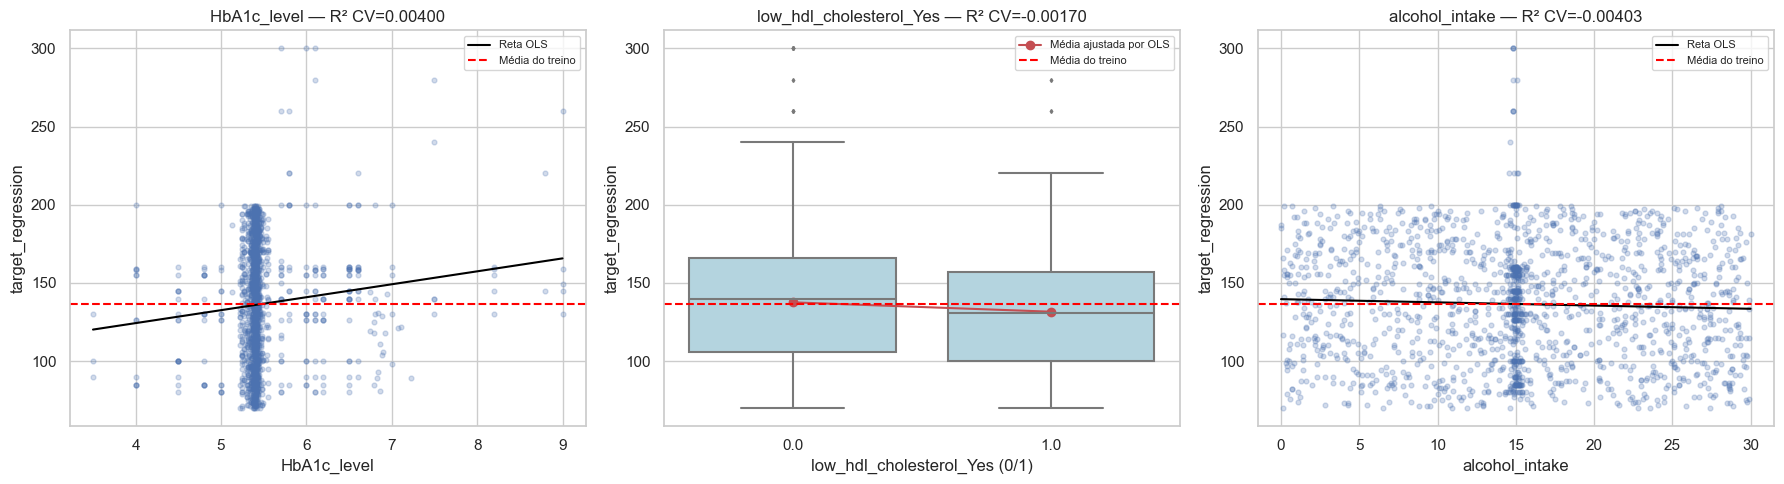

Os gráficos mostram **automaticamente as três melhores colunas por CV**, sem excluir a segunda colocada por ser binária. As linhas são ajustes no treino, usados para interpretação; a evidência de generalização é a CV da tabela. A associação fraca da EDA ajuda a explicar as retas pouco informativas e a elevada dispersão dentro de cada grupo.

In [13]:
fig,axes=plt.subplots(1,len(simple_candidates),figsize=(18,5))
for ax,feat in zip(np.atleast_1d(axes),simple_candidates):
    fitted=make_pipeline(StandardScaler(),LinearRegression()).fit(X_all[[feat]],y_reg)
    score=res_simple_all.set_index('feature').loc[feat,'R2 CV']
    values=np.sort(X_all[feat].unique())
    if len(values)==2:
        sns.boxplot(x=X_all[feat],y=y_reg,ax=ax,color='lightblue',fliersize=2)
        pred=fitted.predict(pd.DataFrame({feat:values}))
        ax.plot(range(2),pred,'ro-',label='Média ajustada por OLS')
        ax.set_xlabel(feat+' (0/1)')
    else:
        ax.scatter(X_all[feat],y_reg,alpha=.25,s=12)
        xs=np.linspace(X_all[feat].min(),X_all[feat].max(),100)
        ax.plot(xs,fitted.predict(pd.DataFrame({feat:xs})),color='black',label='Reta OLS')
        ax.set_xlabel(feat)
    ax.axhline(y_reg.mean(),ls='--',color='red',label='Média do treino')
    ax.set(title=f'{feat} — R² CV={score:.5f}',ylabel='target_regression')
    ax.legend(fontsize=8)
plt.tight_layout();plt.show()
display(Markdown('Os gráficos mostram **automaticamente as três melhores colunas por CV**, '
    'sem excluir a segunda colocada por ser binária. As linhas são ajustes no treino, usados para '
    'interpretação; a evidência de generalização é a CV da tabela. A associação fraca da EDA '
    'ajuda a explicar as retas pouco informativas e a elevada dispersão dentro de cada grupo.'))

### 2.2 Regressão múltipla e adição de preditores
Comparam-se grupos clínicos e modelos com 2, 3, 5 ou 10 colunas escolhidas por associação com o alvo.
Nos Top-k, `SelectKBest` é ajustado dentro de cada fold, evitando que o alvo da validação participe
na escolha. Os grupos clínicos são definidos a priori. As colunas finais dos Top-k serão mostradas
depois do ajuste ao treino completo. Assim, aumentar o número de preditores tem uma avaliação explícita.

In [14]:
def cols_with(prefixes):
    return [c for c in X_all if any(c==p or c.startswith(p+'_') for p in prefixes)]
groups={
 'Laboratório':['HbA1c_level','cholesterol','triglycerides','hdl','ldl','ldl_alternative','crp_level','homocysteine_level','plasma_value'],
 'Tensão/cardíaco':['blood_pressure','systolic_bp','diastolic_bp','heart_rate'],
 'Estilo de vida':['sleep_hours','alcohol_intake','salt_intake']+cols_with(['smoking','physical_activity','stress_level','sugar_consumption']),
 'Demográficas':['age','bmi']+cols_with(['gender','family_history','education_level','employment_status']),
 'Flags colesterol':cols_with(['low_hdl_cholesterol','high_ldl_cholesterol'])+['hdl','ldl','cholesterol'],
 'Todas':list(X_all.columns)}

# SelectKBest com função explícita de passagem para grupos fixos mantém a seleção dentro do pipeline.
from sklearn.compose import ColumnTransformer
def fixed_columns(cols):return ColumnTransformer([('cols','passthrough',list(cols))],remainder='drop')
multi_models={name:make_pipeline(fixed_columns(cols),StandardScaler(),LinearRegression()) for name,cols in groups.items()}
for k in [2,3,5,10]:
    multi_models[f'Top-{k} (seleção no fold)']=Pipeline([
        ('scale',StandardScaler()),('select',SelectKBest(f_regression,k=k)),('model',LinearRegression())])
res_multi=pd.DataFrame([reg_cv_row(name,model) for name,model in multi_models.items()]).set_index('modelo').sort_values('R2 CV',ascending=False)
best_group=res_multi.index[0]
display(res_multi.round(5))
display(Markdown(f'O grupo escolhido por R² CV é **{best_group}** '
    f'({res_multi.loc[best_group,"R2 CV"]:.5f}). Acrescentar colunas não garante melhorar: '
    'com pouco sinal, a complexidade adicional pode ajustar variações da amostra. '
    'O ranking Top-k é marginal e não constitui prova de causalidade ou utilidade isolada.'))

,R2 CV,DP R2 entre folds,MAE CV,RMSE CV
modelo,,,,
Top-2 (seleção no fold),0.00236,0.01001,31.30490,37.35439
Laboratório,-0.00244,0.01486,31.42685,37.43671
Top-3 (seleção no fold),-0.00261,0.01430,31.37375,37.44776
Top-5 (seleção no fold),-0.00609,0.01179,31.36003,37.51022
Tensão/cardíaco,-0.00781,0.00625,31.41560,37.54122
Estilo de vida,-0.00895,0.01518,31.29069,37.56842
Flags colesterol,-0.00979,0.00878,31.41779,37.57675
Top-10 (seleção no fold),-0.01191,0.01761,31.42807,37.61978
Demográficas,-0.01200,0.01560,31.43869,37.60893


O grupo escolhido por R² CV é **Top-2 (seleção no fold)** (0.00236). Acrescentar colunas não garante melhorar: com pouco sinal, a complexidade adicional pode ajustar variações da amostra. O ranking Top-k é marginal e não constitui prova de causalidade ou utilidade isolada.

### 2.3 Escolhas de regressão antes do teste
A seleção não é alterada por um resultado favorável de um concorrente no teste. As diferenças entre
treino, CV e teste serão analisadas na secção 5. Significância OLS convencional depois de selecionar
variáveis pelo alvo não é apresentada como confirmação independente da seleção.

### 2.4 Análises complementares de regressão: pré-processamento, modelos polinomiais e regularização
Avaliam-se extensões dos modelos de regressão com validação apenas no treino. Excluir as categóricas muda o
espaço de informação; codificá-las não é o mesmo que normalizar. Na OLS, reescalar as colunas não
deverá mudar materialmente as previsões, embora mude os coeficientes. Em métodos penalizados,
a escala afeta a penalização, pelo que é ajustada no pipeline.

Testam-se também graus 2/3 numa feature escolhida por associação dentro de cada fold e Ridge/Lasso/Elastic Net na regressão.
A escolha de alpha ocorre numa CV interna com o escalonamento dentro do pipeline e é avaliada
em CV5 externa. Estes modelos são extensões; os dois modelos exigidos na secção 2 continuam a ser
a regressão linear simples e a múltipla selecionadas acima.

Nos polinómios, SelectKBest(k=1) escolhe a coluna por F de regressão apenas no treino de cada fold. Assim, esta extensão avalia também a seleção da coluna, em vez de reutilizar globalmente a variável vencedora da procura anterior. É um procedimento distinto da seleção da regressão simples pelo R² CV.

In [15]:
numeric_only=[c for c in X_all if c in df.select_dtypes(include='number').columns]
ablation_reg=[]
for label,cols in [('Só medidas numéricas',numeric_only),('Numéricas + one-hot',list(X_all))]:
    for scale in [False,True]:
        steps=[('cols',fixed_columns(cols))]
        if scale:steps.append(('scale',StandardScaler()))
        steps.append(('model',LinearRegression()))
        ablation_reg.append({'encoding':label,'escala':scale,**reg_cv_row(label,Pipeline(steps))})
display(pd.DataFrame(ablation_reg).drop(columns='modelo').round(5))
alphas=np.logspace(-2,3,12)
reg_extensions={}
for degree in [2,3]:
    reg_extensions[f'Polinomial grau {degree} (seleção no fold)']=make_pipeline(
        StandardScaler(),SelectKBest(f_regression,k=1),PolynomialFeatures(degree,include_bias=False),LinearRegression())
inner_reg=KFold(3,shuffle=True,random_state=SEED+3)
for name,estimator in [('Ridge',Ridge()),('Lasso',Lasso(max_iter=10000)),
                        ('Elastic Net',ElasticNet(max_iter=10000))]:
    grid={'model__alpha':alphas}
    if name=='Elastic Net':grid['model__l1_ratio']=[.25,.5,.75]
    pipe=Pipeline([('scale',StandardScaler()),('model',estimator)])
    reg_extensions[name]=GridSearchCV(pipe,grid,cv=inner_reg,scoring='neg_mean_squared_error',error_score='raise')
reg_extension_cv=pd.DataFrame([reg_cv_row(name,model) for name,model in reg_extensions.items()]).set_index('modelo')
display(reg_extension_cv.sort_values('R2 CV',ascending=False).round(5))
display(Markdown('A tabela verifica se a não linearidade univariada ou a contração acrescentam '
    'sinal ao sugerido na EDA. Os resultados são estimativas em CV e não uma confirmação de '
    'relações clínicas. O teste final não foi usado para escolher estas configurações.'))

best_extension=reg_extension_cv['R2 CV'].idxmax()
best_extension_r2=reg_extension_cv.loc[best_extension,'R2 CV']
simple_r2=res_simple_all.loc[0,'R2 CV']
numeric_ols=next(r for r in ablation_reg if r['encoding']=='Só medidas numéricas' and r['escala'])
full_ols=next(r for r in ablation_reg if r['encoding']=='Numéricas + one-hot' and r['escala'])
display(Markdown(f'**Resultado da ablação e das extensões.** A OLS com medidas numéricas teve R² CV '
    f'{numeric_ols["R2 CV"]:.5f}; com one-hot, {full_ols["R2 CV"]:.5f}. '
    'A inclusão de mais informação potencial não garantiu melhor previsão: também aumentou a complexidade. '
    f'A melhor extensão foi **{best_extension}**, com R² CV **{best_extension_r2:.5f}**, '
    f'comparado com **{simple_r2:.5f}** da simples escolhida. '
    'Se o ganho for pequeno ou negativo, os resultados não sustentam acrescentar complexidade apenas '
    'porque a técnica foi lecionada. A concordância com a fraca associação marginal da EDA é '
    'uma explicação possível, não uma demonstração de ausência de relações não lineares.'))

,encoding,escala,R2 CV,DP R2 entre folds,MAE CV,RMSE CV
0,Só medidas numéricas,False,-0.00815,0.02281,31.50300,37.54119
1,Só medidas numéricas,True,-0.00815,0.02281,31.50300,37.54119
2,Numéricas + one-hot,False,-0.01636,0.01716,31.45855,37.69692
3,Numéricas + one-hot,True,-0.01636,0.01716,31.45855,37.69692


,R2 CV,DP R2 entre folds,MAE CV,RMSE CV
modelo,,,,
Lasso,0.00210,0.00582,31.24893,37.35640
Polinomial grau 2 (seleção no fold),0.00192,0.00902,31.30460,37.35798
Polinomial grau 3 (seleção no fold),0.00076,0.00923,31.31478,37.38018
Ridge,-0.00079,0.00972,31.26018,37.41011
Elastic Net,-0.00299,0.00620,31.31701,37.44949


A tabela verifica se a não linearidade univariada ou a contração acrescentam sinal ao sugerido na EDA. Os resultados são estimativas em CV e não uma confirmação de relações clínicas. O teste final não foi usado para escolher estas configurações.

**Resultado da ablação e das extensões.** A OLS com medidas numéricas teve R² CV -0.00815; com one-hot, -0.01636. A inclusão de mais informação potencial não garantiu melhor previsão: também aumentou a complexidade. A melhor extensão foi **Lasso**, com R² CV **0.00210**, comparado com **0.00400** da simples escolhida. Se o ganho for pequeno ou negativo, os resultados não sustentam acrescentar complexidade apenas porque a técnica foi lecionada. A concordância com a fraca associação marginal da EDA é uma explicação possível, não uma demonstração de ausência de relações não lineares.

## 3. Classificação — `target_class`
O núcleo pedido é regressão logística e LDA. A referência logística é **sem penalização**; Ridge e
Lasso serão estudados separadamente, evitando chamar “sem regularização” ao `LogisticRegression()`
que usa L2 por defeito. O LDA assume covariância comum por classe; a EDA mostrou limitações dessa hipótese.

O critério principal é **F1 macro**, dando peso igual às classes e equilibrando precision e recall.
Balanced accuracy (= recall macro) e recall por classe complementam-no. Não foi fornecida uma matriz
de custos clínicos que permita afirmar qual o compromisso clínico ótimo.

In [16]:
def lr(C=1.,penalty=None):
    return LogisticRegression(C=C,penalty=penalty,solver='saga' if penalty=='l1' else 'lbfgs',
                              max_iter=10000,tol=1e-4,random_state=SEED)
def scaled(estimator):return make_pipeline(StandardScaler(),estimator)
base_models={'Baseline maioritária':DummyClassifier(strategy='most_frequent'),
             'Logística':scaled(lr()),'LDA':scaled(LinearDiscriminantAnalysis())}
CORE=['Logística','LDA']
scoring={'Accuracy':'accuracy','Balanced Acc':'balanced_accuracy',
 'F1 macro':make_scorer(f1_score,average='macro',labels=LABELS,zero_division=0),
 'Precision macro':make_scorer(precision_score,average='macro',labels=LABELS,zero_division=0),
 'Recall macro':make_scorer(recall_score,average='macro',labels=LABELS,zero_division=0)}
def cls_scores(y,pred):
    return {'Accuracy':accuracy_score(y,pred),'Balanced Acc':balanced_accuracy_score(y,pred),
      'F1 macro':f1_score(y,pred,labels=LABELS,average='macro',zero_division=0),
      'Precision macro':precision_score(y,pred,labels=LABELS,average='macro',zero_division=0),
      'Recall macro':recall_score(y,pred,labels=LABELS,average='macro',zero_division=0)}
resampling=[]

### 3.1 Holdout interno ao treino
O holdout abaixo estima a sensibilidade a uma partição simples sem consumir o teste reservado.
O treino desta experiência é 80% dos 1600 pacientes de desenvolvimento, não os 1600 completos.

In [17]:
a,b,c,d=train_test_split(X_all,y_cls,test_size=.2,stratify=y_cls,random_state=SEED)
for name,model in base_models.items():
    resampling.append({'método':'Holdout interno','modelo':name,**cls_scores(d,clone(model).fit(a,c).predict(b))})
display(pd.DataFrame(resampling).set_index('modelo').round(4))

,método,Accuracy,Balanced Acc,F1 macro,Precision macro,Recall macro
modelo,,,,,,
Baseline maioritária,Holdout interno,0.9031,0.3333,0.3164,0.3010,0.3333
Logística,Holdout interno,0.9188,0.5942,0.6131,0.6586,0.5942
LDA,Holdout interno,0.9312,0.6825,0.6779,0.7145,0.6825


### 3.2 Validação cruzada com k=5 e k=10
A estratificação conserva aproximadamente as proporções das classes. O DP entre folds descreve
a dispersão desses resultados, mas não é o erro-padrão da média nem um intervalo de confiança:
os treinos dos folds sobrepõem-se. Com k maior, cada teste contém menos pacientes minoritários.

In [18]:
cv_details={}
for k in [5,10]:
    rows=[]
    for name,model in base_models.items():
        r=cross_validate(model,X_all,y_cls,cv=StratifiedKFold(k,shuffle=True,random_state=SEED),scoring=scoring,error_score='raise')
        cv_details[(k,name)]=r
        means={m:r['test_'+m].mean() for m in scoring}
        resampling.append({'método':f'CV{k}','modelo':name,**means})
        rows.append({'modelo':name,**means,'DP F1 entre folds':r['test_F1 macro'].std(ddof=1)})
    print(f'CV{k}:');display(pd.DataFrame(rows).set_index('modelo').round(4))

CV5:
CV10:


,Accuracy,Balanced Acc,F1 macro,Precision macro,Recall macro,DP F1 entre folds
modelo,,,,,,
Baseline maioritária,0.9012,0.3333,0.3160,0.3004,0.3333,0.0003
Logística,0.9181,0.5778,0.5822,0.6032,0.5778,0.0322
LDA,0.9188,0.6144,0.6095,0.6378,0.6144,0.0420


,Accuracy,Balanced Acc,F1 macro,Precision macro,Recall macro,DP F1 entre folds
modelo,,,,,,
Baseline maioritária,0.9013,0.3333,0.3160,0.3004,0.3333,0.0005
Logística,0.9206,0.5862,0.5946,0.6271,0.5862,0.0494
LDA,0.9169,0.6037,0.5877,0.6236,0.6037,0.0632


### 3.3 Leave-One-Out (LOOCV)
Cada paciente é previsto por um modelo ajustado aos outros n−1. Reúnem-se todas as previsões antes
de calcular as métricas multiclasse: um fold com apenas um paciente não permite um F1 macro
individual comparável. O custo é elevado e os treinos muito semelhantes; ser determinístico não
significa que o estimador tenha variância estatística nula.

In [19]:
loo_predictions={}
for name in CORE:
    t=time.perf_counter()
    pred=cross_val_predict(base_models[name],X_all,y_cls,cv=LeaveOneOut(),n_jobs=1)
    loo_predictions[name]=pred
    resampling.append({'método':'LOOCV','modelo':name,**cls_scores(y_cls,pred)})
    progress(f'LOOCV {name} concluído em {time.perf_counter()-t:.1f} s')
display(pd.DataFrame(resampling).query("método=='LOOCV'").set_index('modelo').round(4))

[progresso] LOOCV Logística concluído em 104.3 s
[progresso] LOOCV LDA concluído em 42.2 s


,método,Accuracy,Balanced Acc,F1 macro,Precision macro,Recall macro
modelo,,,,,,
Logística,LOOCV,0.9225,0.5895,0.5991,0.6590,0.5895
LDA,LOOCV,0.9200,0.6131,0.6000,0.6341,0.6131


### 3.4 Bootstrap out-of-bag
Cada réplica amostra n pacientes com reposição e avalia exclusivamente os não selecionados (OOB).
Espera-se cerca de 63,2% de pacientes distintos no treino e 36,8% OOB. Os dois algoritmos usam as
mesmas réplicas e todo o pipeline é reajustado em cada uma. O DP por réplica OOB não é diretamente
equivalente ao DP de médias de CV repetida.

In [20]:
rng=np.random.default_rng(SEED)
boot={name:[] for name in CORE};oob_fractions=[]
for b in range(B):
    bag=rng.choice(len(X_all),len(X_all),replace=True)
    oob=np.setdiff1d(np.arange(len(X_all)),np.unique(bag))
    assert set(bag).isdisjoint(oob)
    oob_fractions.append(len(oob)/len(X_all))
    for name in CORE:
        model=clone(base_models[name]).fit(X_all.iloc[bag],y_cls.iloc[bag])
        boot[name].append(cls_scores(y_cls.iloc[oob],model.predict(X_all.iloc[oob])))
for name in CORE:
    resampling.append({'método':'Bootstrap OOB','modelo':name,**pd.DataFrame(boot[name]).mean().to_dict()})
print('Fração OOB média:',np.mean(oob_fractions))
display(pd.DataFrame(resampling).set_index(['método','modelo']).round(4))

Fração OOB média: 0.36864062500000006


Accuracy  Balanced Acc  F1 macro  \
método          modelo                                                   
Holdout interno Baseline maioritária    0.9031        0.3333    0.3164   
                Logística               0.9188        0.5942    0.6131   
                LDA                     0.9312        0.6825    0.6779   
CV5             Baseline maioritária    0.9012        0.3333    0.3160   
                Logística               0.9181        0.5778    0.5822   
                LDA                     0.9188        0.6144    0.6095   
CV10            Baseline maioritária    0.9013        0.3333    0.3160   
                Logística               0.9206        0.5862    0.5946   
                LDA                     0.9169        0.6037    0.5877   
LOOCV           Logística               0.9225        0.5895    0.5991   
                LDA                     0.9200        0.6131    0.6000   
Bootstrap OOB   Logística               0.9146        0.5817    0.5878   
                LDA                     0.9191        0.6122    0.6088   

                                      Precision macro  Recall macro  
método          modelo                                               
Holdout interno Baseline maioritária           0.3010        0.3333  
                Logística                      0.6586        0.5942  
                LDA                            0.7145        0.6825  
CV5             Baseline maioritária           0.3004        0.3333  
                Logística                      0.6032        0.5778  
                LDA                            0.6378        0.6144  
CV10            Baseline maioritária           0.3004        0.3333  
                Logística                      0.6271        0.5862  
                LDA                            0.6236        0.6037  
LOOCV           Logística                      0.6590        0.5895  
                LDA                            0.6341        0.6131  
Bootstrap OOB   Logística                      0.6327        0.5817  
                LDA                            0.6469        0.6122

### 3.5 Variabilidade das estimativas e escolha LR/LDA
Os holdouts e as CV repetidas medem a sensibilidade à partição, condicional aos pacientes
disponíveis. A tabela distingue o DP de um holdout, o DP das médias de CV e a dispersão das
réplicas bootstrap OOB. Estes objetos têm interpretações diferentes; a sobreposição dos
treinos impede tratar os folds como observações independentes.

O LOOCV usa n−1 pacientes por ajuste e tem baixo viés associado ao tamanho do treino.
Os treinos muito semelhantes podem produzir estimativas com variância elevada entre amostras;
esta execução não estima essa variância, pelo que o DP é apresentado como “não estimado”.
CV5 e CV10 oferecem compromissos práticos entre tamanho de treino, estabilidade e custo.
A comparação abaixo usa a dispersão efetivamente observada nas repetições.

No bootstrap, cerca de 63,2% dos pacientes são distintos em cada treino. Essa redução da
diversidade pode tornar a avaliação OOB pessimista face a um ajuste na amostra completa.
O DP das réplicas descreve a dispersão observada e não é apresentado como intervalo de confiança.

,modelo,método,F1 médio,DP
0,Logística,Holdout individual,0.5974,0.0396
1,Logística,Média CV5 repetida,0.5852,0.0148
2,Logística,Média CV10 repetida,0.5908,0.0106
3,Logística,Réplica bootstrap OOB,0.5878,0.0383
4,Logística,LOOCV (DP não estimado),0.5991,NaN
5,LDA,Holdout individual,0.6007,0.0389
6,LDA,Média CV5 repetida,0.6052,0.0115
7,LDA,Média CV10 repetida,0.6003,0.0072
8,LDA,Réplica bootstrap OOB,0.6088,0.0358
9,LDA,LOOCV (DP não estimado),0.6000,NaN


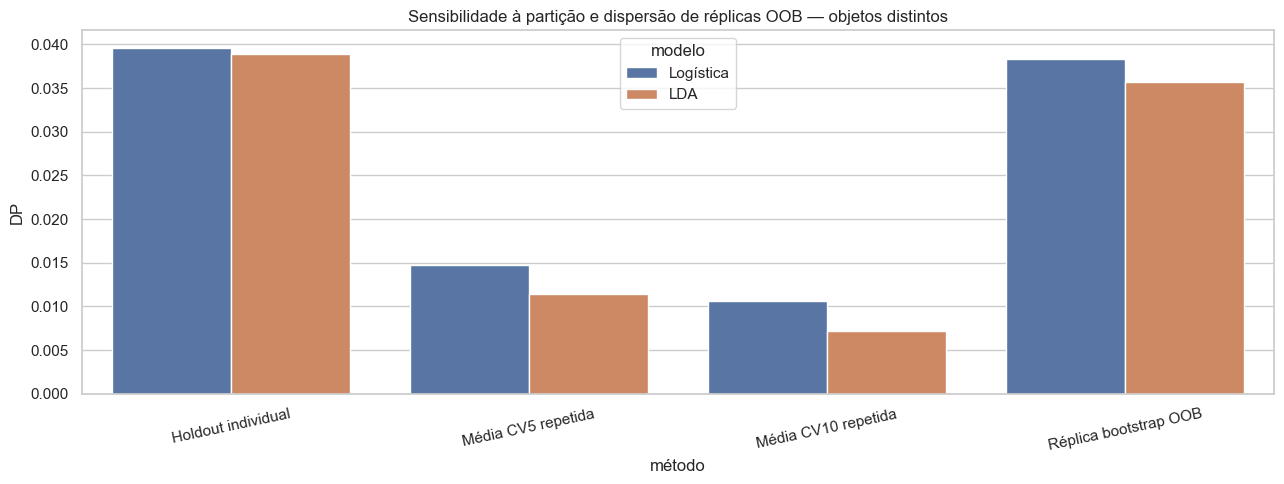

Escolhe-se **LDA** entre os dois métodos pedidos, pelo maior F1 macro médio na CV10 repetida do treino. A diferença é **0.0095**. Uma diferença pequena não demonstra superioridade universal. A EDA ajuda a interpretar os resultados: desequilíbrio penaliza as minorias, e diferenças de dispersão podem escapar a fronteiras lineares. Não se escolhe LDA apenas por existirem três classes; a logística multinomial também admite várias classes.

**Estabilidade observada.** Logística: DP das médias CV5=0.0148; CV10=0.0106. LDA: DP das médias CV5=0.0115; CV10=0.0072. Estes valores descrevem a sensibilidade à partição nesta amostra. A CV10 repetida é o critério definido para comparar logística e LDA; o resultado não estabelece uma vantagem universal de CV10 sobre os restantes métodos.

In [21]:
variance_rows=[];repeats={}
for name in CORE:
    hold=[]
    for seed in range(N_HOLDOUT_REPEATS):
        a,b,c,d=train_test_split(X_all,y_cls,test_size=.2,stratify=y_cls,random_state=seed)
        hold.append(f1_score(d,clone(base_models[name]).fit(a,c).predict(b),average='macro',zero_division=0))
    variance_rows.append({'modelo':name,'método':'Holdout individual','F1 médio':np.mean(hold),'DP':np.std(hold,ddof=1)})
    for k in [5,10]:
        values=np.array([cross_val_score(base_models[name],X_all,y_cls,
            cv=StratifiedKFold(k,shuffle=True,random_state=seed),scoring=scoring['F1 macro'],error_score='raise').mean()
            for seed in range(N_CV_REPEATS)])
        repeats[(name,k)]=values
        variance_rows.append({'modelo':name,'método':f'Média CV{k} repetida','F1 médio':values.mean(),'DP':values.std(ddof=1)})
    bf=pd.DataFrame(boot[name])['F1 macro']
    variance_rows.append({'modelo':name,'método':'Réplica bootstrap OOB','F1 médio':bf.mean(),'DP':bf.std(ddof=1)})
    variance_rows.append({'modelo':name,'método':'LOOCV (DP não estimado)','F1 médio':cls_scores(y_cls,loo_predictions[name])['F1 macro'],'DP':np.nan})
variance_table=pd.DataFrame(variance_rows)
display(variance_table.round(4))
fig,ax=plt.subplots(figsize=(13,5))
sns.barplot(data=variance_table.dropna(subset=['DP']),x='método',y='DP',hue='modelo',errorbar=None,ax=ax)
ax.set_title('Sensibilidade à partição e dispersão de réplicas OOB — objetos distintos')
ax.tick_params(axis='x',rotation=12);plt.tight_layout();plt.show()
core_choice=max(CORE,key=lambda name:repeats[(name,10)].mean())
gap=abs(repeats[('Logística',10)].mean()-repeats[('LDA',10)].mean())
display(Markdown(f'Escolhe-se **{core_choice}** entre os dois métodos pedidos, pelo maior F1 macro médio '
    f'na CV10 repetida do treino. A diferença é **{gap:.4f}**. Uma diferença pequena não demonstra '
    'superioridade universal. A EDA ajuda a interpretar os resultados: desequilíbrio penaliza as '
    'minorias, e diferenças de dispersão podem escapar a fronteiras lineares. Não se escolhe LDA '
    'apenas por existirem três classes; a logística multinomial também admite várias classes.'))

stability=[]
for name in CORE:
    d5=repeats[(name,5)].std(ddof=1)
    d10=repeats[(name,10)].std(ddof=1)
    stability.append(f'{name}: DP das médias CV5={d5:.4f}; CV10={d10:.4f}.')
display(Markdown('**Estabilidade observada.** '+' '.join(stability)+
    ' Estes valores descrevem a sensibilidade à partição nesta amostra. A CV10 repetida '
    'é o critério definido para comparar logística e LDA; o resultado não estabelece '
    'uma vantagem universal de CV10 sobre os restantes métodos.'))


### 3.6 Encoding, normalização e ponderação de classes
O estudo de ablação distingue o contributo das medidas numéricas e da informação
categórica codificada. Compara-se com/sem escalonamento e uma logística com `class_weight='balanced'`.
Esta ponderação muda o compromisso de erros; não garante maior F1 ou melhor utilidade clínica.
Não se escolhem limiares olhando para o teste. O LDA é, em condições numéricas regulares, invariante
a reescalamentos lineares invertíveis, pelo que a escala pode não alterar os seus resultados.

Neste estudo de ablação, a logística sem penalização é resolvida por Newton-CG nos dois cenários de escala, mantendo o mesmo objetivo. Isto evita interpretar uma falha de convergência do solver como uma diferença de capacidade preditiva. Os restantes ensaios usam os solvers indicados nas suas definições.

In [22]:
ablation_cls=[]
for label,cols in [('Só medidas numéricas',numeric_only),('Numéricas + one-hot',list(X_all))]:
    for scale in [False,True]:
        for name,estimator in [('Logística',LogisticRegression(penalty=None,solver='newton-cg',max_iter=5000,tol=1e-4,random_state=SEED)),('LDA',LinearDiscriminantAnalysis())]:
            steps=[('cols',fixed_columns(cols))]
            if scale:steps.append(('scale',StandardScaler()))
            steps.append(('model',estimator))
            r=cross_validate(Pipeline(steps),X_all,y_cls,
                cv=StratifiedKFold(5,shuffle=True,random_state=SEED),scoring=scoring,error_score='raise')
            ablation_cls.append({'modelo':name,'encoding':label,'escala':scale,
                                **{m:r['test_'+m].mean() for m in scoring}})
weighted=scaled(LogisticRegression(penalty=None,class_weight='balanced',max_iter=10000,random_state=SEED))
r=cross_validate(weighted,X_all,y_cls,cv=StratifiedKFold(5,shuffle=True,random_state=SEED),scoring=scoring,error_score='raise')
ablation_cls.append({'modelo':'Logística ponderada','encoding':'Numéricas + one-hot','escala':True,
                    **{m:r['test_'+m].mean() for m in scoring}})
display(pd.DataFrame(ablation_cls).round(5))

ablation_frame=pd.DataFrame(ablation_cls)
details=[]
for name in CORE:
    base=ablation_frame[(ablation_frame.modelo==name)&(ablation_frame.encoding=='Só medidas numéricas')&(ablation_frame.escala)]
    enc=ablation_frame[(ablation_frame.modelo==name)&(ablation_frame.encoding=='Numéricas + one-hot')&(ablation_frame.escala)]
    raw_scale=ablation_frame[(ablation_frame.modelo==name)&(ablation_frame.encoding=='Numéricas + one-hot')&(~ablation_frame.escala)]
    details.append(f'{name}: F1 CV5 só numéricas={base["F1 macro"].iloc[0]:.3f}; '
        f'com one-hot={enc["F1 macro"].iloc[0]:.3f}; sem escala={raw_scale["F1 macro"].iloc[0]:.3f}.')
weighted_row=ablation_frame[ablation_frame.modelo=='Logística ponderada'].iloc[0]
display(Markdown('**Leitura da ablação.** '+' '.join(details)+
    f' A logística ponderada teve F1={weighted_row["F1 macro"]:.3f} e balanced accuracy='
    f'{weighted_row["Balanced Acc"]:.3f}. As categóricas podem transportar associação com a classe, '
    'como observado nos testes da EDA; isso é diferente de um benefício de reescalamento. '
    'A ponderação dá maior peso às minorias, mas o compromisso deve ser lido simultaneamente '
    'em F1 e balanced accuracy. Não se escolhe uma abordagem apenas porque melhora uma métrica.'))

,modelo,encoding,escala,Accuracy,Balanced Acc,F1 macro,Precision macro,Recall macro
0,Logística,Só medidas numéricas,False,0.91938,0.55582,0.55588,0.58061,0.55582
1,LDA,Só medidas numéricas,False,0.91625,0.58243,0.55664,0.55678,0.58243
2,Logística,Só medidas numéricas,True,0.91938,0.55582,0.55588,0.58061,0.55582
3,LDA,Só medidas numéricas,True,0.91625,0.58243,0.55664,0.55678,0.58243
4,Logística,Numéricas + one-hot,False,0.91813,0.57779,0.58223,0.60324,0.57779
5,LDA,Numéricas + one-hot,False,0.91875,0.61441,0.60945,0.63776,0.61441
6,Logística,Numéricas + one-hot,True,0.91813,0.57779,0.58223,0.60324,0.57779
7,LDA,Numéricas + one-hot,True,0.91875,0.61441,0.60945,0.63776,0.61441
8,Logística ponderada,Numéricas + one-hot,True,0.74875,0.71161,0.55759,0.53264,0.71161


**Leitura da ablação.** Logística: F1 CV5 só numéricas=0.556; com one-hot=0.582; sem escala=0.582. LDA: F1 CV5 só numéricas=0.557; com one-hot=0.609; sem escala=0.609. A logística ponderada teve F1=0.558 e balanced accuracy=0.712. As categóricas podem transportar associação com a classe, como observado nos testes da EDA; isso é diferente de um benefício de reescalamento. A ponderação dá maior peso às minorias, mas o compromisso deve ser lido simultaneamente em F1 e balanced accuracy. Não se escolhe uma abordagem apenas porque melhora uma métrica.

### 3.7 Extensão fundamentada: QDA
O QDA admite covariâncias distintas por classe, motivado pelos DP muito diferentes da secção 1.3.
Usa-se `reg_param=0.01` fixado antes do teste para estabilizar covariâncias. Não se assume que todas
as features, sobretudo dummies, sejam gaussianas: é uma aproximação cuja utilidade é avaliada por CV.
Esta extensão não substitui a comparação obrigatória LR/LDA.

In [23]:
qda=scaled(QuadraticDiscriminantAnalysis(reg_param=.01))
qda_cv_rows=[]
for k in [5,10]:
    r=cross_validate(qda,X_all,y_cls,cv=StratifiedKFold(k,shuffle=True,random_state=SEED),scoring=scoring,error_score='raise')
    qda_cv_rows.append({'k':k,**{m:r['test_'+m].mean() for m in scoring},'DP F1':r['test_F1 macro'].std(ddof=1)})
qda_cv=pd.DataFrame(qda_cv_rows).set_index('k')
display(qda_cv.round(4))

,Accuracy,Balanced Acc,F1 macro,Precision macro,Recall macro,DP F1
k,,,,,,
5,0.9006,0.8012,0.7003,0.6493,0.8012,0.0622
10,0.9013,0.8487,0.7237,0.6706,0.8487,0.0662


## 4. Regularização e escolha aprofundada de C
### 4.1 Critérios definidos antes da pesquisa e do teste
Na logística, C pequeno significa regularização forte. Ridge (L2) contrai os coeficientes; Lasso (L1)
pode anulá-los. As colunas, incluindo dummies, são padronizadas no treino de cada fold.

A escolha de C combina desempenho observado em CV e parcimónia, segundo três regras explícitas:

- **Máximo:** maior F1 macro médio; empates numéricos favorecem o menor C.
- **Equilibrado:** menor C cujo F1 fica até **0,01** abaixo do máximo.
- **Compacto:** menor C cujo F1 fica até **0,03** abaixo do máximo.

As tolerâncias são operacionais (1 e 3 pontos percentuais de F1), não testes de significância nem
garantias de equivalência. Menor C favorece esparsidade, mas não garante monotonicidade do número
de colunas: os números reais são sempre mostrados. Menos preditores é parcimónia, não uma medição de tempo.

**Pesquisa automática:** grelha ampla logarítmica; expansão se o máximo estiver na fronteira superior;
dois refinamentos locais em torno do máximo e das zonas dos dois compromissos. Os intervalos e valores
novos são gerados a partir dos resultados de treino, sem índices escolhidos à mão e sem consultar o teste.

In [24]:
def choose_cs(table):
    t=table.sort_values('C').reset_index(drop=True)
    best=float(t.F1_CV.max())
    # A grelha é crescente: menor C entre empates e entre candidatos dentro da tolerância.
    return {
        'Máximo':float(t.loc[t.F1_CV>=best-1e-12,'C'].iloc[0]),
        'Equilibrado':float(t.loc[t.F1_CV>=best-TOL_BALANCED-1e-12,'C'].iloc[0]),
        'Compacto':float(t.loc[t.F1_CV>=best-TOL_COMPACT-1e-12,'C'].iloc[0])}

def adaptive_search(X,y,penalty,n_splits=3,with_counts=False):
    cache={};splitter=StratifiedKFold(n_splits,shuffle=True,random_state=SEED+7)
    def evaluate(values,stage):
        for value in sorted(set(float(v) for v in values)):
            key=float(f'{value:.12g}')
            if key in cache:continue
            scores=cross_val_score(scaled(lr(key,penalty)),X,y,cv=splitter,
                                   scoring=scoring['F1 macro'],error_score='raise')
            row={'C':key,'F1_CV':scores.mean(),'DP_folds':scores.std(ddof=1),'fase':stage}
            if with_counts:
                fit=scaled(lr(key,penalty)).fit(X,y)
                row['N_ativos']=int((np.abs(fit[-1].coef_)>1e-6).any(axis=0).sum())
            cache[key]=row
    def table():return pd.DataFrame(cache.values()).sort_values('C').reset_index(drop=True)
    evaluate(np.logspace(-3,2,13),'ampla')
    for expansion in range(2):
        t=table();bestC=choose_cs(t)['Máximo']
        if not np.isclose(bestC,t.C.max()):break
        evaluate(np.geomspace(t.C.max(),t.C.max()*10,5)[1:],f'expansão {expansion+1}')
    for stage,points in [(1,9),(2,7)]:
        t=table();new=[]
        for center in set(choose_cs(t).values()):
            pos=int(np.argmin(abs(np.log(t.C/center))))
            low=float(t.C.iloc[max(0,pos-1)]);high=float(t.C.iloc[min(len(t)-1,pos+1)])
            if low==high:continue
            new.extend(np.geomspace(low,high,points))
        evaluate(new,f'local {stage}')
    t=table()
    return t,choose_cs(t)

progress('Pesquisa final de C no treino: L2')
ridge_path,ridge_cs=adaptive_search(X_all,y_cls,'l2',n_splits=5,with_counts=True)
progress('Pesquisa final de C no treino: L1')
lasso_path,lasso_cs=adaptive_search(X_all,y_cls,'l1',n_splits=5,with_counts=True)
C_ridge=ridge_cs['Máximo']
print('Nº de C avaliados — Ridge:',len(ridge_path),'| Lasso:',len(lasso_path))
print('C Ridge:',C_ridge,'| C Lasso:',lasso_cs)
display(ridge_path.round(7))
display(lasso_path.round(7))

choice_rows=[]
for strategy,C in lasso_cs.items():
    row=lasso_path.iloc[np.argmin(abs(np.log(lasso_path.C/C)))].to_dict()
    choice_rows.append({'solução Lasso':strategy,**row,'perda F1 face ao máximo':lasso_path.F1_CV.max()-row['F1_CV']})
choice_table=pd.DataFrame(choice_rows).set_index('solução Lasso')
display(choice_table.round(7))

[progresso] Pesquisa final de C no treino: L2
[progresso] Pesquisa final de C no treino: L1
Nº de C avaliados — Ridge: 43 | Lasso: 36
C Ridge: 0.180694296456 | C Lasso: {'Máximo': 1.33352143216, 'Equilibrado': 0.248790236724, 'Compacto': 0.16681005372}


,C,F1_CV,DP_folds,fase,N_ativos
0,0.001000,0.316020,0.000316,ampla,34
1,0.002610,0.407988,0.046811,ampla,34
2,0.006813,0.475135,0.048867,ampla,34
3,0.017783,0.547215,0.042280,ampla,34
4,0.022603,0.541116,0.046681,local 1,34
5,0.028730,0.560478,0.039301,local 1,34
6,0.036517,0.575033,0.021515,local 1,34
7,0.038007,0.575033,0.021515,local 2,34
8,0.039557,0.577282,0.028889,local 2,34
9,0.041170,0.578903,0.023336,local 2,34


,C,F1_CV,DP_folds,fase,N_ativos
0,0.001000,0.316020,0.000316,ampla,0
1,0.002610,0.316020,0.000316,ampla,0
2,0.006813,0.316020,0.000316,ampla,1
3,0.017783,0.495942,0.053795,ampla,2
4,0.046416,0.557245,0.043920,ampla,7
5,0.058998,0.562503,0.047899,local 1,11
6,0.074989,0.569512,0.047267,local 1,14
7,0.095316,0.574413,0.048413,local 1,16
8,0.121153,0.575308,0.033507,ampla,21
9,0.153993,0.579264,0.048995,local 1,22


,C,F1_CV,DP_folds,fase,N_ativos,perda F1 face ao máximo
solução Lasso,,,,,,
Máximo,1.333521,0.609887,0.027886,local 1,32,0.000000
Equilibrado,0.248790,0.600488,0.032491,local 1,25,0.009399
Compacto,0.166810,0.582830,0.043444,local 2,23,0.027057


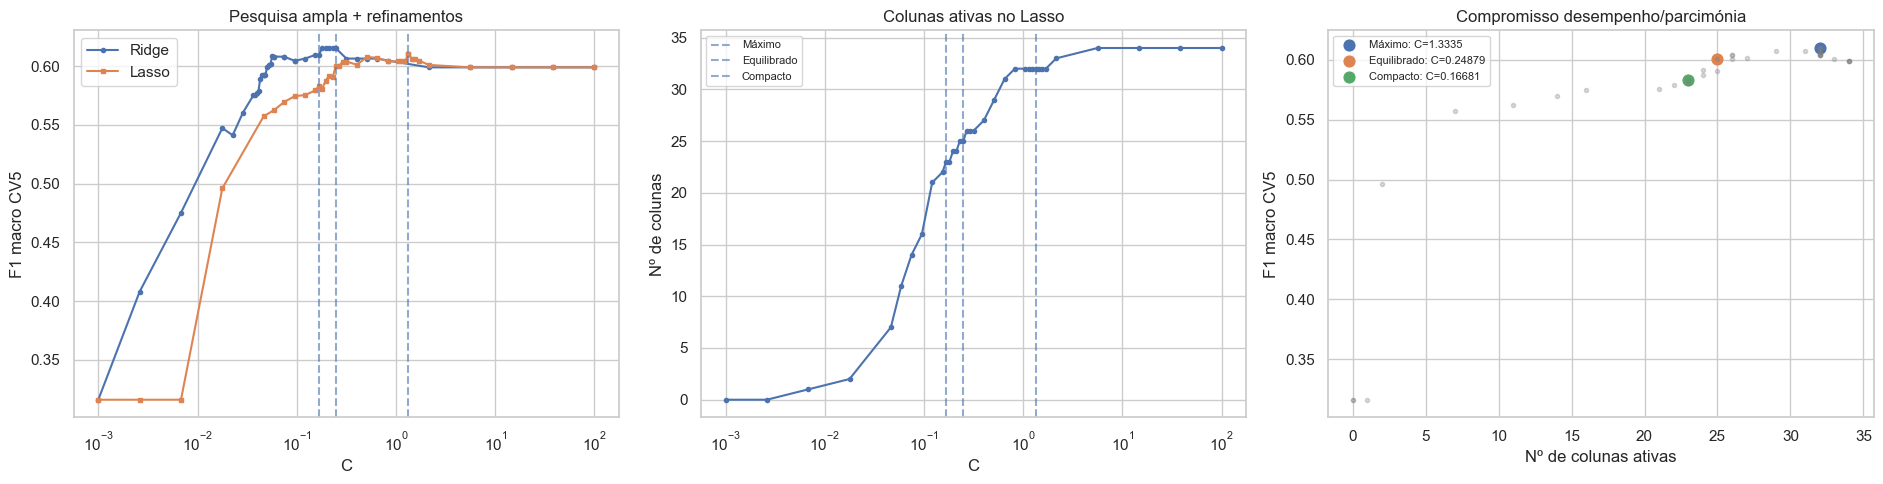

Os máximos locais e pequenas oscilações podem refletir a amostra e as partições. A pesquisa mais fina melhora a resolução da grelha, não elimina essa incerteza. A tabela mostra explicitamente o custo em F1 e o número de colunas; não se declara um ótimo universal.

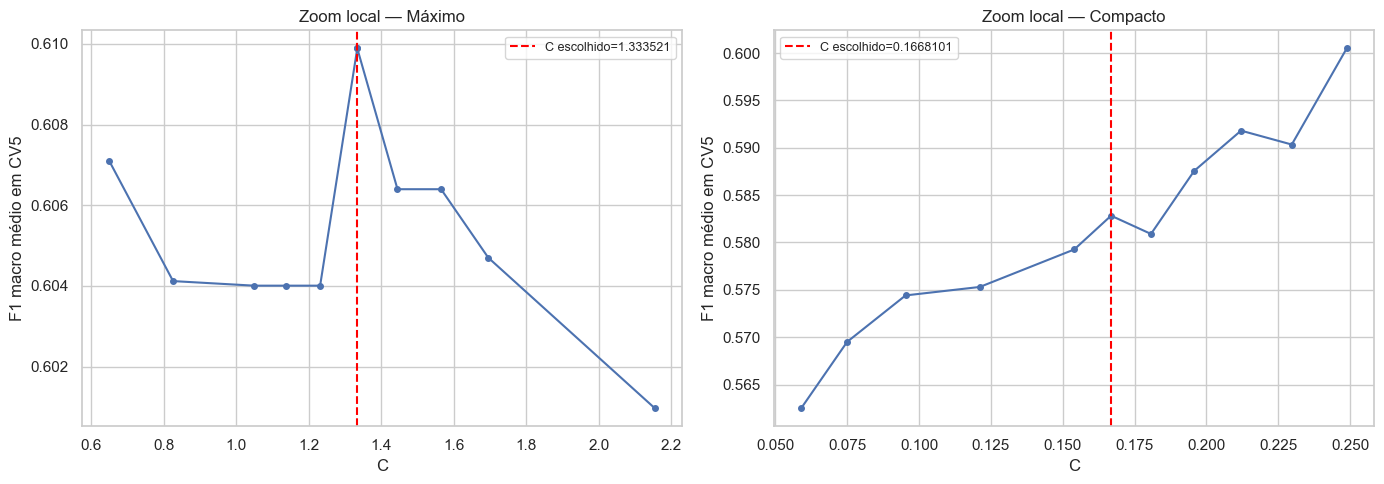

**Ajuste fino local.** As ampliações mostram os candidatos vizinhos que a grelha ampla não distinguia. Reportam-se médias observadas em CV, com a dispersão disponível na tabela. Um máximo estreito ou uma diferença nas últimas casas decimais pode refletir a partição; a CV externa avalia se o procedimento de pesquisa generaliza.

In [25]:
fig,axes=plt.subplots(1,3,figsize=(19,5))
axes[0].semilogx(ridge_path.C,ridge_path.F1_CV,'o-',ms=3,label='Ridge')
axes[0].semilogx(lasso_path.C,lasso_path.F1_CV,'s-',ms=3,label='Lasso')
axes[0].set(title='Pesquisa ampla + refinamentos',xlabel='C',ylabel='F1 macro CV5');axes[0].legend()
axes[1].semilogx(lasso_path.C,lasso_path.N_ativos,'o-',ms=3)
axes[1].set(title='Colunas ativas no Lasso',xlabel='C',ylabel='Nº de colunas')
for name,C in lasso_cs.items():
    for ax in axes[:2]:ax.axvline(C,ls='--',alpha=.6,label=name)
    row=choice_table.loc[name]
    axes[2].scatter(row['N_ativos'],row['F1_CV'],s=60,label=f'{name}: C={C:.5g}')
axes[1].legend(fontsize=8)
axes[2].plot(lasso_path.N_ativos,lasso_path.F1_CV,'.',alpha=.3,color='gray')
axes[2].set(title='Compromisso desempenho/parcimónia',xlabel='Nº de colunas ativas',ylabel='F1 macro CV5')
axes[2].legend(fontsize=8)
plt.tight_layout();plt.show()
display(Markdown('Os máximos locais e pequenas oscilações podem refletir a amostra e as partições. '
    'A pesquisa mais fina melhora a resolução da grelha, não elimina essa incerteza. A tabela mostra '
    'explicitamente o custo em F1 e o número de colunas; não se declara um ótimo universal.'))

# Ampliação dos intervalos efetivamente refinados para visualizar diferenças de C próximas.
fig,axes=plt.subplots(1,2,figsize=(14,5))
for ax,strategy in zip(axes,['Máximo','Compacto']):
    center=lasso_cs[strategy]
    ordered=lasso_path.sort_values('C').reset_index(drop=True)
    pos=int(np.argmin(abs(np.log(ordered.C/center))))
    zoom=ordered.iloc[max(0,pos-5):min(len(ordered),pos+6)]
    ax.plot(zoom.C,zoom.F1_CV,'o-',ms=4)
    ax.axvline(center,ls='--',color='red',label=f'C escolhido={center:.7g}')
    ax.set(title=f'Zoom local — {strategy}',xlabel='C',ylabel='F1 macro médio em CV5')
    ax.legend(fontsize=9);ax.ticklabel_format(axis='x',style='plain',useOffset=False)
plt.tight_layout();plt.show()
display(Markdown('**Ajuste fino local.** As ampliações mostram os candidatos vizinhos que a grelha '
    'ampla não distinguia. Reportam-se médias observadas em CV, com a dispersão disponível na tabela. '
    'Um máximo estreito ou uma diferença nas últimas casas decimais pode refletir a partição; '
    'a CV externa avalia se o procedimento de pesquisa generaliza.'))

### 4.2 Avaliação dos procedimentos por CV aninhada
Escolher C e reportar a mesma CV como avaliação final introduziria otimismo. Por isso, comparam-se
os procedimentos em **CV5 externa**; em cada fold externo, repete-se a pesquisa adaptativa com
**CV3 interna** usando apenas o treino desse fold. Os modelos completos usam os mesmos folds externos.
A pesquisa final da secção 4.1 usa CV5 no treino completo para preparar o ajuste final.

Distinguem-se a logística L1 direta e o procedimento **selecionar por L1 e reajustar logística/LDA**.
Os seus resultados não são intercambiáveis: os coeficientes depois do reajuste são diferentes.

In [26]:
def selected_model(C,estimator):
    return Pipeline([('scale',StandardScaler()),
        ('select',SelectFromModel(lr(C,'l1'),threshold=1e-6)),('model',estimator)])

outer=StratifiedKFold(5,shuffle=True,random_state=SEED)
nested_rows=[];nested_details=[]
for fold,(fit_idx,val_idx) in enumerate(outer.split(X_all,y_cls),1):
    Xfit,Xval=X_all.iloc[fit_idx],X_all.iloc[val_idx]
    yfit,yval=y_cls.iloc[fit_idx],y_cls.iloc[val_idx]
    progress(f'CV aninhada: fold {fold}/5 — pesquisa L1/L2')
    rp,rc=adaptive_search(Xfit,yfit,'l2',n_splits=N_INNER_SEARCH)
    lp,lc=adaptive_search(Xfit,yfit,'l1',n_splits=N_INNER_SEARCH)
    models={'Logística completa':scaled(lr()),'LDA completa':scaled(LinearDiscriminantAnalysis()),
            'Ridge':scaled(lr(rc['Máximo'],'l2'))}
    for strategy,C in lc.items():
        models['Lasso '+strategy]=scaled(lr(C,'l1'))
        models['Seleção L1 → LR '+strategy]=selected_model(C,lr())
        models['Seleção L1 → LDA '+strategy]=selected_model(C,LinearDiscriminantAnalysis())
    for name,model in models.items():
        fitted=model.fit(Xfit,yfit);pred=fitted.predict(Xval)
        if 'select' in fitted.named_steps:n=int(fitted.named_steps['select'].get_support().sum())
        elif name.startswith('Lasso'):n=int((abs(fitted[-1].coef_)>1e-6).any(axis=0).sum())
        else:n=N_FEATURES
        nested_rows.append({'procedimento':name,'fold':fold,'colunas':n,**cls_scores(yval,pred)})
    nested_details.append({'fold':fold,'C Ridge':rc['Máximo'],**{'C Lasso '+s:c for s,c in lc.items()},
                           'n C L1':len(lp),'n C L2':len(rp)})

nested_folds=pd.DataFrame(nested_rows)
selection_cv=nested_folds.groupby('procedimento',sort=False).agg(
    F1_CV_externa=('F1 macro','mean'),DP_F1_folds=('F1 macro','std'),
    Balanced_acc_CV=('Balanced Acc','mean'),colunas_médias=('colunas','mean'))
display(selection_cv.round(5))
display(pd.DataFrame(nested_details).round(7))
display(Markdown('As colunas médias podem diferir das do ajuste final, porque a seleção muda entre '
    'folds. Uma diferença pequena de F1 não demonstra superioridade ou equivalência estatística. '
    'O teste final permitirá auditar estes procedimentos sem voltar a escolher C com base nele.'))

[progresso] CV aninhada: fold 1/5 — pesquisa L1/L2
[progresso] CV aninhada: fold 2/5 — pesquisa L1/L2
[progresso] CV aninhada: fold 3/5 — pesquisa L1/L2
[progresso] CV aninhada: fold 4/5 — pesquisa L1/L2
[progresso] CV aninhada: fold 5/5 — pesquisa L1/L2


,F1_CV_externa,DP_F1_folds,Balanced_acc_CV,colunas_médias
procedimento,,,,
Logística completa,0.58223,0.03224,0.57779,34.0
LDA completa,0.60945,0.04203,0.61441,34.0
Ridge,0.58826,0.02891,0.57825,34.0
Lasso Máximo,0.58632,0.03131,0.57802,33.0
Seleção L1 → LR Máximo,0.58223,0.03224,0.57779,33.0
Seleção L1 → LDA Máximo,0.60945,0.04203,0.61441,33.0
Lasso Equilibrado,0.58237,0.03355,0.58133,31.2
Seleção L1 → LR Equilibrado,0.58378,0.03161,0.58245,31.2
Seleção L1 → LDA Equilibrado,0.60498,0.03340,0.61070,31.2


,fold,C Ridge,C Lasso Máximo,C Lasso Equilibrado,C Lasso Compacto,n C L1,n C L2
0,1,0.825404,4.424186,1.049140,0.180694,45,38
1,2,1.136464,2.738420,0.401945,0.111844,40,38
2,3,1.444516,1.564748,1.564748,1.231056,31,37
3,4,0.291929,31.370958,2.333757,0.166810,45,30
4,5,0.111844,0.599484,0.553421,0.269498,30,34


As colunas médias podem diferir das do ajuste final, porque a seleção muda entre folds. Uma diferença pequena de F1 não demonstra superioridade ou equivalência estatística. O teste final permitirá auditar estes procedimentos sem voltar a escolher C com base nele.

### 4.3 Importância, variáveis anuladas e comparação com a EDA
Para **cada C escolhido automaticamente**, calcula-se a soma dos coeficientes absolutos nas três
classes, após padronização, e aplica-se a mesma tolerância de 1e-6 para identificar colunas ativas.
É uma medida de importância **condicional a este modelo e C**, não importância causal ou universal.

ANOVA/Cramér V descrevem associação marginal com `target_class`; correlação com `target_regression`
responde a outra tarefa e não pode confirmar diretamente a importância na classificação.
Um coeficiente anulado identifica uma coluna dispensada por esta solução penalizada.
A coluna pode ser redundante ou contribuir para modelos que aproveitem diferenças de dispersão,
possibilidade discutida a partir da EDA e dos resultados do QDA.

In [27]:
selected_sets={};importance_tables={};final_lasso_models={}
def original_feature(column):
    matches=[c for c in CATEGORIES if column.startswith(c+'_')]
    return max(matches,key=len) if matches else column

for strategy,C in lasso_cs.items():
    model=scaled(lr(C,'l1')).fit(X_all,y_cls)
    weights=abs(model[-1].coef_).sum(axis=0)
    mask=(abs(model[-1].coef_)>1e-6).any(axis=0)
    table=pd.DataFrame({'Preditor':X_all.columns,'Importância Σ|β|':weights,
                         'Estado':np.where(mask,'Ativo','Anulado neste C')})
    table['Variável original']=table.Preditor.map(original_feature)
    table['F ANOVA EDA']=table['Variável original'].map(anova['F ANOVA (descritivo)'])
    table['Cramér V EDA']=table['Variável original'].map(chi['Cramér V'])
    table=table.sort_values('Importância Σ|β|',ascending=False).reset_index(drop=True)
    importance_tables[strategy]=table
    selected_sets[strategy]=X_all.columns[mask].tolist()
    final_lasso_models[strategy]=model
    print(f'\n{strategy}: C={C:.9g}; {mask.sum()}/{N_FEATURES} colunas ativas')
    display(table.round(5))
    print('Anuladas:',X_all.columns[~mask].tolist())

max_table=importance_tables['Máximo']
top_model=max_table.loc[max_table.Estado=='Ativo'].head(5)['Preditor'].tolist()
top_eda=anova.loc[anova.index.isin(RAW_FEATURES)].head(3).index.tolist()
overlap=[c for c in top_model if original_feature(c) in top_eda]
display(Markdown(f'No modelo Lasso máximo, as primeiras colunas são **{", ".join(top_model)}**. '
    f'Entre elas, **{", ".join(overlap) if overlap else "nenhuma"}** coincide(m) com as três primeiras '
    'medidas retidas da ANOVA. A concordância apoia a interpretação; diferenças são esperáveis porque a '
    'ANOVA é marginal e o Lasso condiciona nas restantes colunas e na penalização.'))

dispersion_cols=['systolic_bp','diastolic_bp','salt_intake','heart_rate','hdl','ldl']
audit_dispersion=[]
for c in dispersion_cols:
    row={'Preditor':c,**{s:('Ativo' if c in keep else 'Anulado') for s,keep in selected_sets.items()}}
    for cl in LABELS:row['DP '+cl]=df.loc[df.target_class==cl,c].std()
    audit_dispersion.append(row)
display(pd.DataFrame(audit_dispersion).round(4))
display(Markdown('**Dispersão e seleção.** Esta tabela relaciona a seleção L1 com a variabilidade por classe. '
    'Mesmo quando o Lasso anula uma coluna, DP muito diferentes por classe podem continuar a '
    'contribuir para o QDA. A ausência de coeficiente linear não prova ausência de informação.'))

weak_active=max_table[(max_table.Estado=='Ativo')&(max_table['F ANOVA EDA']<1)].Preditor.tolist()
if weak_active:
    display(Markdown('**Discordâncias úteis para a análise.** No Lasso máximo, '
        f'**{", ".join(weak_active)}** ficou/ficaram ativo(s) apesar de F ANOVA inferior a 1. '
        'Um coeficiente condicional e uma diferença marginal de médias medem coisas distintas. '
        'A seleção pode refletir dependência com outras colunas ou flutuação da amostra; não '
        'constitui confirmação clínica. Por isso se reporta a CV externa e a estabilidade entre folds, '
        'em vez de declarar todas as variáveis retidas importantes ou todas as anuladas ruído.'))


Máximo: C=1.33352143; 32/34 colunas ativas
Anuladas: ['systolic_bp', 'salt_intake']

Equilibrado: C=0.248790237; 25/34 colunas ativas
Anuladas: ['sleep_hours', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'stress_level_Medium', 'sugar_consumption_Low']

Compacto: C=0.166810054; 23/34 colunas ativas
Anuladas: ['cholesterol', 'sleep_hours', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'stress_level_Medium', 'sugar_consumption_Low']


,Preditor,Importância Σ|β|,Estado,Variável original,F ANOVA EDA,Cramér V EDA
0,HbA1c_level,2.44073,Ativo,HbA1c_level,711.20867,NaN
1,triglycerides,1.22900,Ativo,triglycerides,75.26653,NaN
2,physical_activity_Low,1.01394,Ativo,physical_activity,NaN,0.13466
3,employment_status_Retired,0.82858,Ativo,employment_status,NaN,0.03955
4,age,0.68089,Ativo,age,14.70729,NaN
5,bmi,0.65913,Ativo,bmi,7.18965,NaN
6,smoking_Never,0.58223,Ativo,smoking,NaN,0.07489
7,high_ldl_cholesterol_Yes,0.57801,Ativo,high_ldl_cholesterol,NaN,0.05235
8,smoking_Former,0.55301,Ativo,smoking,NaN,0.07489
9,family_history_Yes,0.52140,Ativo,family_history,NaN,0.05890


,Preditor,Importância Σ|β|,Estado,Variável original,F ANOVA EDA,Cramér V EDA
0,HbA1c_level,2.02887,Ativo,HbA1c_level,711.20867,NaN
1,triglycerides,1.08570,Ativo,triglycerides,75.26653,NaN
2,physical_activity_Low,0.61344,Ativo,physical_activity,NaN,0.13466
3,age,0.56844,Ativo,age,14.70729,NaN
4,bmi,0.45743,Ativo,bmi,7.18965,NaN
5,smoking_Never,0.39925,Ativo,smoking,NaN,0.07489
6,low_hdl_cholesterol_Yes,0.38517,Ativo,low_hdl_cholesterol,NaN,0.17040
7,smoking_Former,0.36015,Ativo,smoking,NaN,0.07489
8,employment_status_Retired,0.34890,Ativo,employment_status,NaN,0.03955
9,physical_activity_Moderate,0.33888,Ativo,physical_activity,NaN,0.13466


,Preditor,Importância Σ|β|,Estado,Variável original,F ANOVA EDA,Cramér V EDA
0,HbA1c_level,1.92868,Ativo,HbA1c_level,711.20867,NaN
1,triglycerides,1.01290,Ativo,triglycerides,75.26653,NaN
2,age,0.51673,Ativo,age,14.70729,NaN
3,physical_activity_Low,0.44605,Ativo,physical_activity,NaN,0.13466
4,bmi,0.37987,Ativo,bmi,7.18965,NaN
5,low_hdl_cholesterol_Yes,0.32526,Ativo,low_hdl_cholesterol,NaN,0.17040
6,smoking_Never,0.31736,Ativo,smoking,NaN,0.07489
7,physical_activity_Moderate,0.29928,Ativo,physical_activity,NaN,0.13466
8,smoking_Former,0.27946,Ativo,smoking,NaN,0.07489
9,gender_Male,0.24974,Ativo,gender,NaN,0.07295


No modelo Lasso máximo, as primeiras colunas são **HbA1c_level, triglycerides, physical_activity_Low, employment_status_Retired, age**. Entre elas, **HbA1c_level, triglycerides, age** coincide(m) com as três primeiras medidas retidas da ANOVA. A concordância apoia a interpretação; diferenças são esperáveis porque a ANOVA é marginal e o Lasso condiciona nas restantes colunas e na penalização.

,Preditor,Máximo,Equilibrado,Compacto,DP HY,DP HT,DP DI_HT
0,systolic_bp,Anulado,Anulado,Anulado,24.5014,0.8362,0.8918
1,diastolic_bp,Ativo,Anulado,Anulado,16.4485,0.3385,0.3737
2,salt_intake,Anulado,Anulado,Anulado,3.5729,0.1078,0.1130
3,heart_rate,Ativo,Anulado,Anulado,13.6702,0.4342,0.3780
4,hdl,Ativo,Anulado,Anulado,19.0794,0.5454,0.6674
5,ldl,Ativo,Ativo,Anulado,33.1800,1.3033,0.8629


**Dispersão e seleção.** Esta tabela relaciona a seleção L1 com a variabilidade por classe. Mesmo quando o Lasso anula uma coluna, DP muito diferentes por classe podem continuar a contribuir para o QDA. A ausência de coeficiente linear não prova ausência de informação.

**Discordâncias úteis para a análise.** No Lasso máximo, **plasma_value, cholesterol, ldl, homocysteine_level, crp_level, sleep_hours, ldl_alternative, heart_rate, diastolic_bp, alcohol_intake, hdl** ficou/ficaram ativo(s) apesar de F ANOVA inferior a 1. Um coeficiente condicional e uma diferença marginal de médias medem coisas distintas. A seleção pode refletir dependência com outras colunas ou flutuação da amostra; não constitui confirmação clínica. Por isso se reporta a CV externa e a estabilidade entre folds, em vez de declarar todas as variáveis retidas importantes ou todas as anuladas ruído.

### 4.4 Caminhos dos coeficientes
Traçam-se 20 valores logaritmicamente distribuídos no intervalo de C pesquisado.
Os caminhos são descritivos, ajustados apenas no treino: mostram contração e entrada/saída de
colunas. Os coeficientes médios absolutos não mostram o sinal do efeito nem constituem nova avaliação de desempenho.

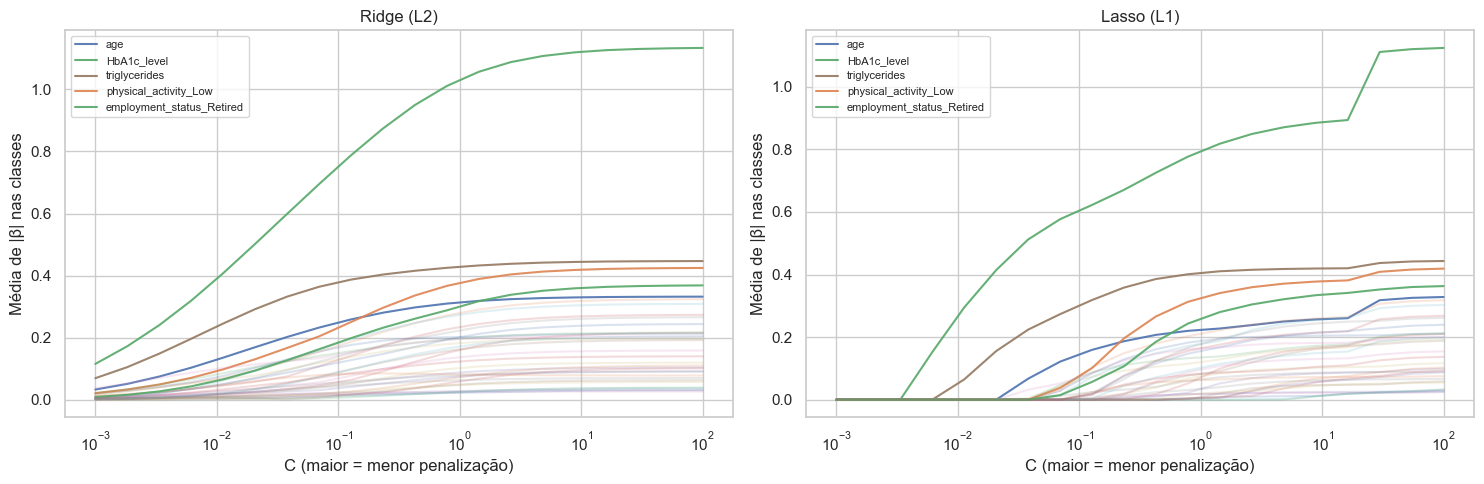

In [28]:
Cs_path=np.geomspace(min(lasso_path.C),max(lasso_path.C),20)
Xs_train=StandardScaler().fit_transform(X_all)
fig,axes=plt.subplots(1,2,figsize=(15,5))
highlight=set(importance_tables['Máximo'].head(5).Preditor)
for ax,pen,title in zip(axes,['l2','l1'],['Ridge (L2)','Lasso (L1)']):
    coefs=np.array([abs(lr(C,pen).fit(Xs_train,y_cls).coef_).mean(axis=0) for C in Cs_path])
    for j,c in enumerate(X_all):
        ax.semilogx(Cs_path,coefs[:,j],label=c if c in highlight else None,alpha=.9 if c in highlight else .2)
    ax.set(title=title,xlabel='C (maior = menor penalização)',ylabel='Média de |β| nas classes')
    ax.legend(fontsize=8)
plt.tight_layout();plt.show()

## 5. Avaliação final no teste reservado
Avaliam-se os modelos e procedimentos definidos no treino, usando os mesmos 400 pacientes
de teste. As escolhas de C e de preditores permanecem fixas durante estas comparações.
As diferenças entre CV e teste descrevem a generalização observada nesta amostra e são
interpretadas à luz do desequilíbrio das classes e do número de pacientes minoritários.

A separação inicial e o ajuste das transformações dentro dos folds sustentam o protocolo
de prevenção de leakage. A repetição da execução no mesmo teste reproduz esta avaliação;
uma validação independente exigiria novos pacientes.

Múltipla (Top-2 (seleção no fold)) → colunas finais: ['HbA1c_level', 'low_hdl_cholesterol_Yes']


,Decisões feitas no treino
Regressão simples,HbA1c_level
Regressão múltipla,Top-2 (seleção no fold)
Escolha LR/LDA,LDA
C Ridge,0.180694
C Lasso Máximo,1.333521
C Lasso Equilibrado,0.24879
C Lasso Compacto,0.16681
QDA reg_param,0.01


,R2 treino,R2 teste,MAE teste,RMSE teste
modelo,,,,
Baseline (média),0.00000,-0.00316,31.61463,37.63103
Simples (HbA1c_level),0.01041,-0.00185,31.80958,37.60630
Múltipla (Top-2 (seleção no fold)),0.01527,0.00827,31.67753,37.41600


A maior redução de RMSE dos dois modelos selecionados face à média é **0.57%**. O desempenho deve ser interpretado pela dimensão do ganho e pelos erros absolutos. R² baixo não distingue, por si só, falta de sinal, ruído ou relações não lineares. A associação fraca na EDA é compatível com pouco poder linear, sem demonstrar imprevisibilidade por todos os métodos.

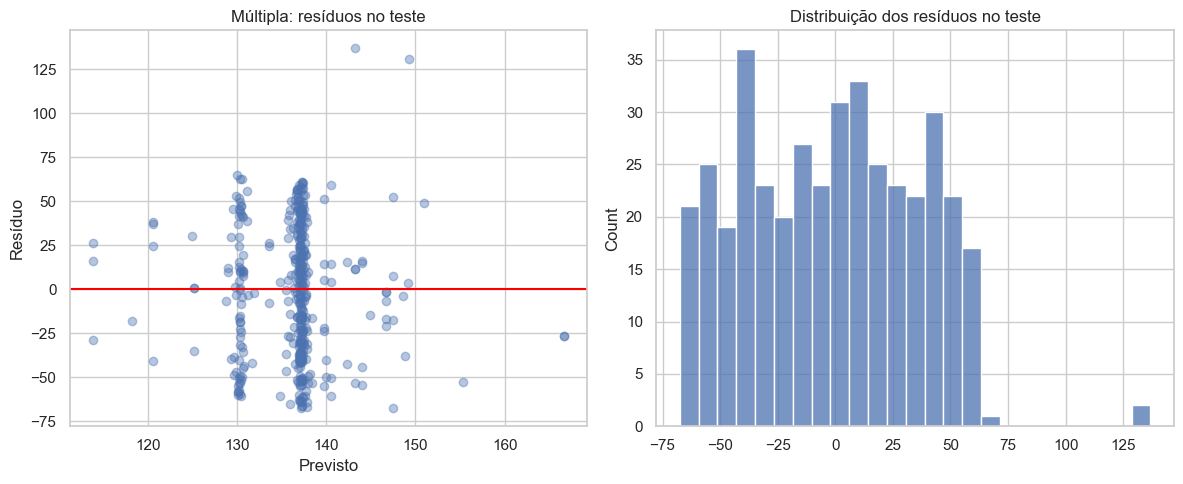

**Comparação simples/múltipla.** O R² CV da simples foi 0.00400 e o do melhor grupo múltiplo foi 0.00236. Pelo critério definido no treino, a preferência entre estes dois é pelo modelo **simples**. A expressão “melhor grupo múltiplo” refere-se ao melhor da sua família e não implica superar a simples. Os resíduos e erros de teste complementam a análise sem alterar essa escolha.

In [29]:
decision_log={'Regressão simples':best_simple,'Regressão múltipla':best_group,'Escolha LR/LDA':core_choice,
              'C Ridge':C_ridge,**{'C Lasso '+s:c for s,c in lasso_cs.items()},'QDA reg_param':.01}
display(pd.Series(decision_log,name='Decisões feitas no treino').to_frame())
reg_models={'Baseline (média)':clone(baseline_reg),
            'Simples ('+best_simple+')':make_pipeline(fixed_columns([best_simple]),StandardScaler(),LinearRegression()),
            'Múltipla ('+best_group+')':clone(multi_models[best_group])}
reg_test_rows=[];reg_predictions={}
for name,model in reg_models.items():
    model.fit(X_all,y_reg);pred=model.predict(X_reserved);reg_predictions[name]=pred
    reg_test_rows.append({'modelo':name,'R2 treino':r2_score(y_reg,model.predict(X_all)),
        'R2 teste':r2_score(yr_reserved,pred),'MAE teste':mean_absolute_error(yr_reserved,pred),
        'RMSE teste':np.sqrt(mean_squared_error(yr_reserved,pred))})
reg_test=pd.DataFrame(reg_test_rows).set_index('modelo')
display(reg_test.round(5))
for name,model in reg_models.items():
    if hasattr(model,'named_steps') and 'select' in model.named_steps:
        print(name,'→ colunas finais:',X_all.columns[model.named_steps['select'].get_support()].tolist())
simple_key,multi_key=list(reg_models)[1:]
gain=100*(reg_test.loc['Baseline (média)','RMSE teste']-reg_test.loc[[simple_key,multi_key],'RMSE teste'].min())/reg_test.loc['Baseline (média)','RMSE teste']
display(Markdown(f'A maior redução de RMSE dos dois modelos selecionados face à média é **{gain:.2f}%**. '
    'O desempenho deve ser interpretado pela dimensão do ganho e pelos erros absolutos. R² baixo '
    'não distingue, por si só, falta de sinal, ruído ou relações não lineares. A associação fraca '
    'na EDA é compatível com pouco poder linear, sem demonstrar imprevisibilidade por todos os métodos.'))

resid=yr_reserved.to_numpy()-reg_predictions[multi_key]
fig,axes=plt.subplots(1,2,figsize=(12,5))
axes[0].scatter(reg_predictions[multi_key],resid,alpha=.4);axes[0].axhline(0,color='red')
axes[0].set(title='Múltipla: resíduos no teste',xlabel='Previsto',ylabel='Resíduo')
sns.histplot(resid,bins=25,ax=axes[1]);axes[1].set_title('Distribuição dos resíduos no teste')
plt.tight_layout();plt.show()

simple_cv_r2=res_simple_all.loc[0,'R2 CV']
multiple_cv_r2=res_multi.loc[best_group,'R2 CV']
preferred_reg='simples' if simple_cv_r2>=multiple_cv_r2 else 'múltiplo'
display(Markdown(f'**Comparação simples/múltipla.** O R² CV da simples foi {simple_cv_r2:.5f} '
    f'e o do melhor grupo múltiplo foi {multiple_cv_r2:.5f}. Pelo critério definido no treino, '
    f'a preferência entre estes dois é pelo modelo **{preferred_reg}**. '
    'A expressão “melhor grupo múltiplo” refere-se ao melhor da sua família e não implica superar '
    'a simples. Os resíduos e erros de teste complementam a análise sem alterar essa escolha.'))


Logística completa
              precision    recall  f1-score   support

          HY       0.93      0.99      0.96       360
          HT       0.67      0.09      0.15        23
       DI_HT       0.81      0.76      0.79        17

    accuracy                           0.93       400
   macro avg       0.80      0.61      0.63       400
weighted avg       0.91      0.93      0.91       400


LDA completa
              precision    recall  f1-score   support

          HY       0.93      0.98      0.96       360
          HT       0.33      0.04      0.08        23
       DI_HT       0.72      0.76      0.74        17

    accuracy                           0.92       400
   macro avg       0.66      0.60      0.59       400
weighted avg       0.89      0.92      0.90       400


Lasso Máximo
              precision    recall  f1-score   support

          HY       0.93      0.99      0.96       360
          HT       0.67      0.09      0.15        23
       DI_HT       0.76    

,Accuracy,Balanced Acc,F1 macro,Precision macro,Recall macro,Recall HY,Recall HT,Recall DI_HT
modelo,,,,,,,,
Baseline maioritária,0.9000,0.33333,0.31579,0.30000,0.33333,1.00000,0.00000,0.00000
Logística completa,0.9275,0.61352,0.63420,0.80452,0.61352,0.98889,0.08696,0.76471
LDA completa,0.9200,0.59717,0.59261,0.66320,0.59717,0.98333,0.04348,0.76471
Ridge,0.9250,0.59391,0.62114,0.79953,0.59391,0.98889,0.08696,0.70588
QDA,0.9125,0.85394,0.72507,0.65526,0.85394,0.92500,0.69565,0.94118
Lasso Máximo,0.9250,0.61259,0.62600,0.78853,0.61259,0.98611,0.08696,0.76471
Seleção L1 → LR Máximo,0.9275,0.61352,0.63420,0.80452,0.61352,0.98889,0.08696,0.76471
Seleção L1 → LDA Máximo,0.9200,0.59717,0.59261,0.66320,0.59717,0.98333,0.04348,0.76471
Lasso Equilibrado,0.9300,0.59576,0.63219,0.92981,0.59576,0.99444,0.08696,0.70588


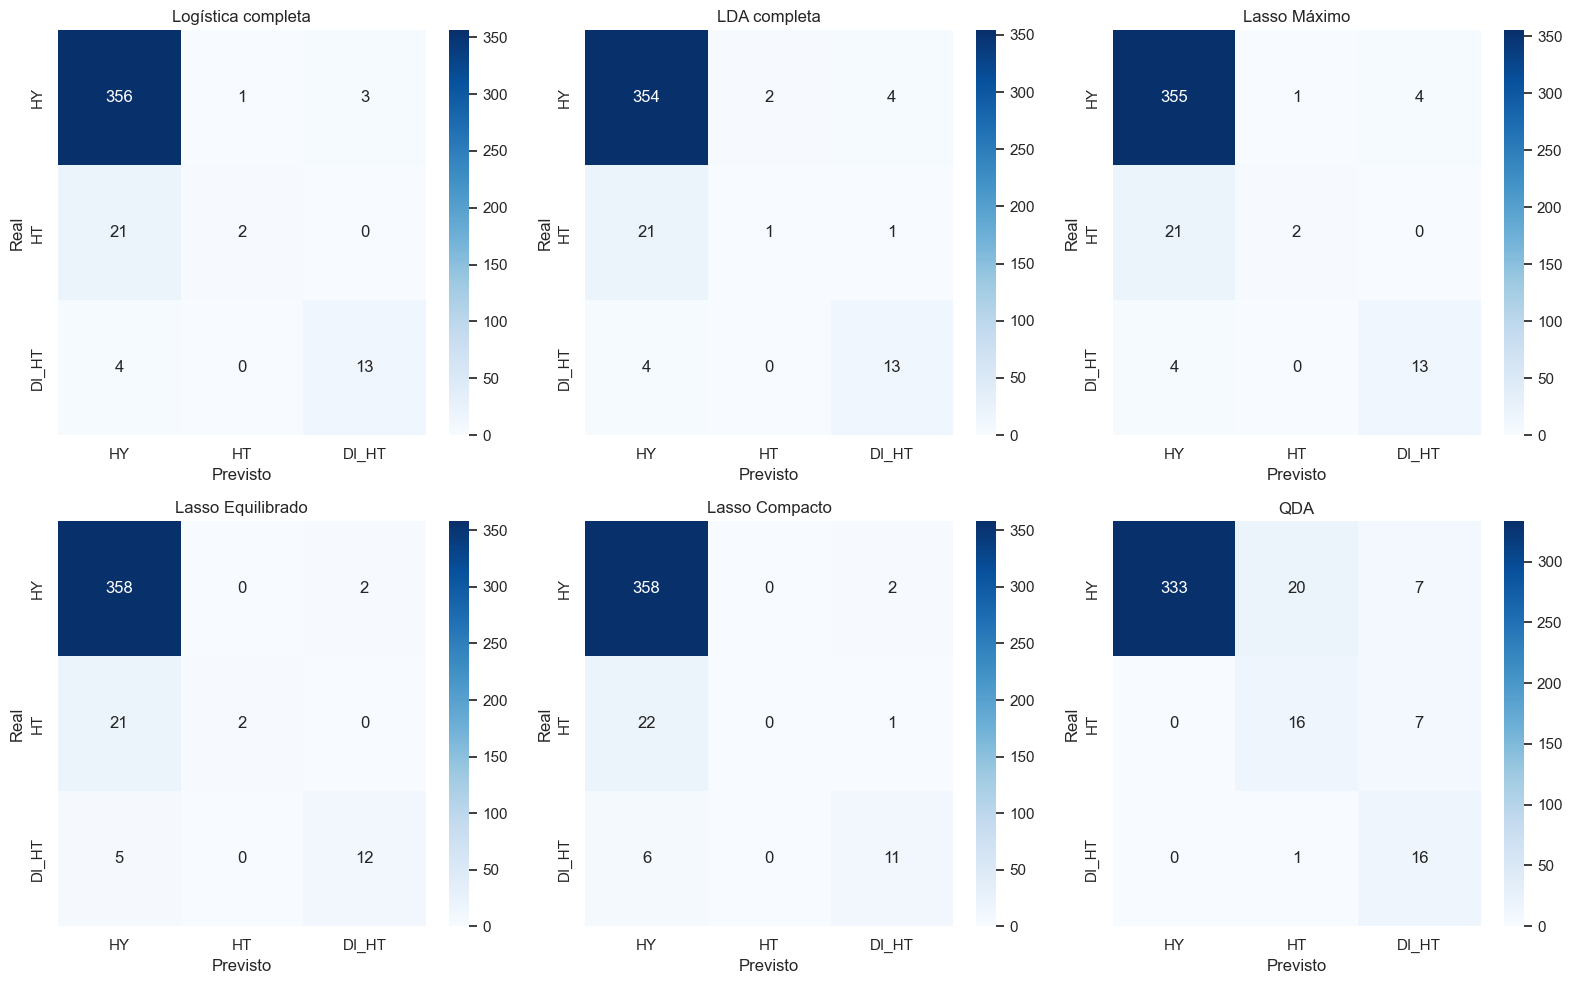

**Procedimentos diferentes.** Máximo: F1 teste L1 direto=0.626; após seleção e reajuste LR=0.634. Equilibrado: F1 teste L1 direto=0.632; após seleção e reajuste LR=0.634. Compacto: F1 teste L1 direto=0.556; após seleção e reajuste LR=0.634. O reajuste altera os coeficientes e a penalização, pelo que não é correto atribuir o seu resultado ao Lasso direto. A comparação relevante para escolher o procedimento continua a ser a CV externa; as diferenças neste teste auditam as escolhas já fixadas.

**Limite do compromisso compacto.** A perda de F1 face ao Lasso máximo foi 0.0271 na CV de escolha de C e 0.0695 neste teste. A tolerância definida no treino não garante a mesma perda em pacientes novos. O Lasso compacto identificou **0/23 pacientes HT** (recall=0.000). A redução de preditores deve ser ponderada contra a perda de deteção das minorias. O resultado do reajuste nas mesmas colunas é apresentado separadamente: a penalização e o reajuste alteram as decisões, não apenas a quantidade de variáveis.

In [30]:
class_models={'Baseline maioritária':clone(base_models['Baseline maioritária']),
              'Logística completa':clone(base_models['Logística']),'LDA completa':clone(base_models['LDA']),
              'Ridge':scaled(lr(C_ridge,'l2')),'QDA':clone(qda)}
for strategy,C in lasso_cs.items():
    class_models['Lasso '+strategy]=clone(final_lasso_models[strategy])
    class_models['Seleção L1 → LR '+strategy]=selected_model(C,lr())
    class_models['Seleção L1 → LDA '+strategy]=selected_model(C,LinearDiscriminantAnalysis())
final_classifiers={};class_predictions={};test_rows=[]
for name,model in class_models.items():
    fitted=model.fit(X_all,y_cls);final_classifiers[name]=fitted
    pred=fitted.predict(X_reserved);class_predictions[name]=pred
    row={'modelo':name,**cls_scores(yc_reserved,pred)}
    for cl in LABELS:row['Recall '+cl]=recall_score(yc_reserved,pred,labels=[cl],average='macro',zero_division=0)
    test_rows.append(row)
class_test=pd.DataFrame(test_rows).set_index('modelo')
display(class_test.round(5))
for name in ['Logística completa','LDA completa','Lasso Máximo','Lasso Compacto','QDA']:
    print('\n'+name);print(classification_report(yc_reserved,class_predictions[name],labels=LABELS,zero_division=0))
fig,axes=plt.subplots(2,3,figsize=(16,10))
plot_names=['Logística completa','LDA completa','Lasso Máximo','Lasso Equilibrado','Lasso Compacto','QDA']
for ax,name in zip(axes.flat,plot_names):
    cm=confusion_matrix(yc_reserved,class_predictions[name],labels=LABELS)
    sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=LABELS,yticklabels=LABELS,ax=ax)
    ax.set(title=name,xlabel='Previsto',ylabel='Real')
plt.tight_layout();plt.show()

tradeoffs=[]
for strategy in lasso_cs:
    direct=class_test.loc['Lasso '+strategy,'F1 macro']
    refit=class_test.loc['Seleção L1 → LR '+strategy,'F1 macro']
    tradeoffs.append(f'{strategy}: F1 teste L1 direto={direct:.3f}; após seleção e reajuste LR={refit:.3f}.')
display(Markdown('**Procedimentos diferentes.** '+' '.join(tradeoffs)+
    ' O reajuste altera os coeficientes e a penalização, pelo que não é correto atribuir o seu '
    'resultado ao Lasso direto. A comparação relevante para escolher o procedimento continua a ser '
    'a CV externa; as diferenças neste teste auditam as escolhas já fixadas.'))

internal_loss=choice_table.loc['Compacto','perda F1 face ao máximo']
test_loss=class_test.loc['Lasso Máximo','F1 macro']-class_test.loc['Lasso Compacto','F1 macro']
ht_recall=class_test.loc['Lasso Compacto','Recall HT']
ht_n=int((yc_reserved=='HT').sum())
ht_correct=int(((yc_reserved=='HT')&(class_predictions['Lasso Compacto']=='HT')).sum())
display(Markdown(f'**Limite do compromisso compacto.** A perda de F1 face ao Lasso máximo foi '
    f'{internal_loss:.4f} na CV de escolha de C e {test_loss:.4f} neste teste. A tolerância '
    'definida no treino não garante a mesma perda em pacientes novos. '
    f'O Lasso compacto identificou **{ht_correct}/{ht_n} pacientes HT** (recall={ht_recall:.3f}). '
    'A redução de preditores deve ser ponderada contra a perda de deteção das minorias. '
    'O resultado do reajuste nas mesmas colunas é apresentado separadamente: a penalização '
    'e o reajuste alteram as decisões, não apenas a quantidade de variáveis.'))

### 5.1 ROC/AUC e interpretação do compromisso
A previsão multiclasse padrão escolhe a classe com maior probabilidade (**argmax**), sem exigir
um limiar binário universal de 0,50. AUC mede ordenação ao variar o limiar e não substitui a avaliação
do ponto de decisão atual. O QDA abaixo é ajustado exclusivamente ao treino. As probabilidades são alinhadas explicitamente com as classes.

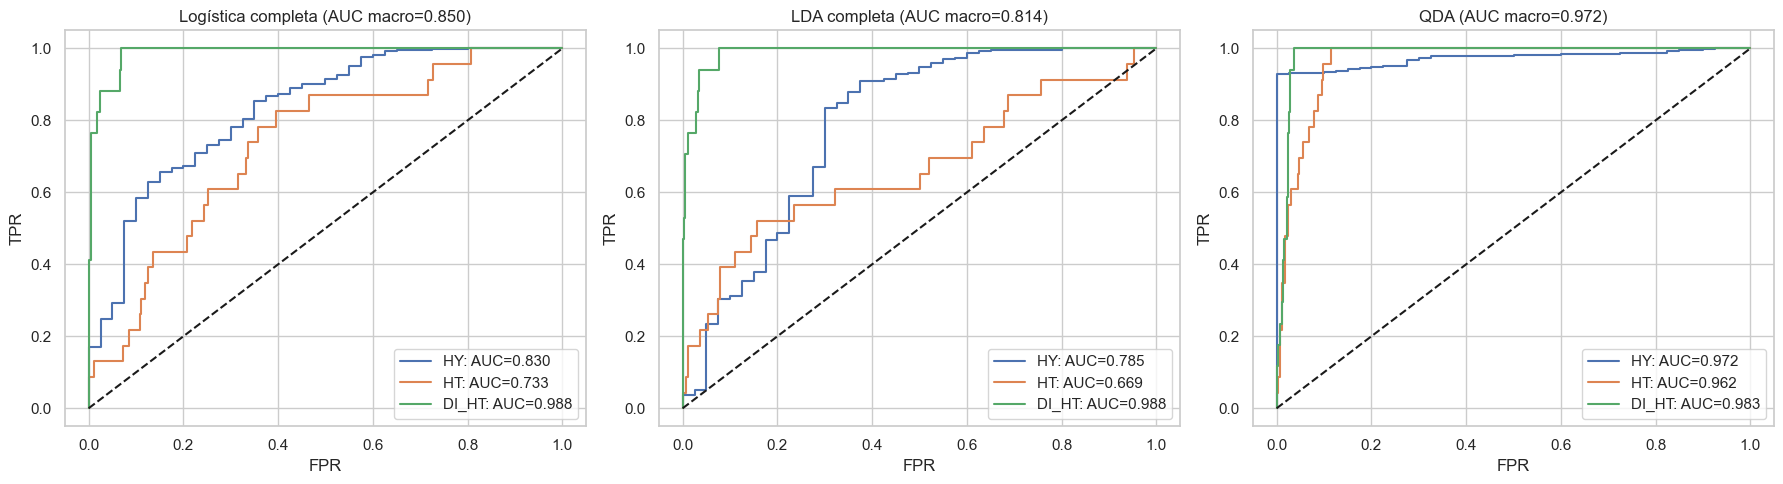

,AUC macro OVR
modelo,
Logística completa,0.85026
LDA completa,0.81429
QDA,0.97197


In [31]:
ybin=label_binarize(yc_reserved,classes=LABELS)
fig,axes=plt.subplots(1,3,figsize=(18,5));auc_rows=[]
for ax,name in zip(axes,['Logística completa','LDA completa','QDA']):
    fitted=final_classifiers[name];probs=fitted.predict_proba(X_reserved)
    order=list(fitted.classes_)
    probs=np.column_stack([probs[:,order.index(cl)] for cl in LABELS])
    assert np.isfinite(probs).all() and np.allclose(probs.sum(axis=1),1)
    for j,cl in enumerate(LABELS):
        fpr,tpr,_=roc_curve(ybin[:,j],probs[:,j]);ax.plot(fpr,tpr,label=f'{cl}: AUC={auc(fpr,tpr):.3f}')
    macro=roc_auc_score(ybin,probs,average='macro');auc_rows.append({'modelo':name,'AUC macro OVR':macro})
    ax.plot([0,1],[0,1],'k--');ax.set(title=f'{name} (AUC macro={macro:.3f})',xlabel='FPR',ylabel='TPR');ax.legend()
plt.tight_layout();plt.show()
display(pd.DataFrame(auc_rows).set_index('modelo').round(5))

## 6. Conclusões globais e justificações
As conclusões sintetizam os resultados calculados nesta execução e a sua relação com a EDA.
A interpretação clínica permanece limitada pelos custos de erro, pela calibração e pela
ausência de validação externa.

In [32]:
preferred_by_cv='simples' if res_simple_all.loc[0,'R2 CV']>=res_multi.loc[best_group,'R2 CV'] else 'múltiplo'
core_test_name='Logística completa' if core_choice=='Logística' else 'LDA completa'
q_improved=qda_cv.loc[10,'F1 macro']>cv_details[(10,core_choice)]['test_F1 macro'].mean()
qtext=('O QDA obteve maior F1 na CV10, compatível com as diferenças de dispersão da EDA.' if q_improved else
       'O QDA não superou o modelo escolhido nesta CV10; a sua maior flexibilidade não garantiu melhor generalização.')
summary=[]
for strategy in lasso_cs:
    name='Lasso '+strategy
    n=len(selected_sets[strategy])
    summary.append(f'- **{strategy}:** C={lasso_cs[strategy]:.7g}; {n}/{N_FEATURES} colunas; '
        f'F1 CV externa={selection_cv.loc[name,"F1_CV_externa"]:.3f}; '
        f'F1 teste={class_test.loc[name,"F1 macro"]:.3f}.')
display(Markdown(f'''
**EDA e preparação.** O treino tem {len(df)} pacientes. O desequilíbrio justifica métricas macro e
recall por classe. Foram retiradas cinco colunas por constância/redundância/convenção de parcimónia,
mantendo-se as suspeitas de pouca utilidade para avaliação. Médias semelhantes não demonstram
distribuições iguais; diferenças de DP ajudam a interpretar o QDA.

**Regressão.** A melhor coluna por CV foi `{best_simple}` e o grupo múltiplo foi `{best_group}`.
No teste, R²={reg_test.loc[simple_key,'R2 teste']:.5f} e {reg_test.loc[multi_key,'R2 teste']:.5f},
respetivamente. Pelo critério de CV definido no treino, a preferência entre os dois é pelo modelo **{preferred_by_cv}**; não se altera essa escolha por uma realização favorável do teste.
A maior redução de RMSE face ao baseline foi {gain:.2f}%.
A fraca correlação marginal da EDA é coerente com pouco sinal linear individual. Acrescentar
preditores foi testado nos Top-k dentro dos folds, sem assumir que maior complexidade seria melhor.
Os resultados não demonstram que nenhum método possa prever o alvo.

**Logística e LDA.** A escolha no treino foi **{core_choice}**, por F1 macro médio na CV10 repetida.
No teste, esse modelo teve F1={class_test.loc[core_test_name,'F1 macro']:.3f}, balanced accuracy=
{class_test.loc[core_test_name,'Balanced Acc']:.3f} e recall HT={class_test.loc[core_test_name,'Recall HT']:.3f}.
A matriz de confusão mostra os erros que a accuracy isolada esconde. A escolha foi mantida mesmo
que outro concorrente obtenha um resultado mais favorável nesta realização do teste.

**Reamostragem.** A repetição de partições mede estabilidade condicional à amostra. O DP entre
folds, o DP entre médias de CV e o DP de réplicas OOB são diferentes. LOOCV não recebeu variância zero;
o seu baixo viés de tamanho de treino tem custo computacional e treinos muito correlacionados.

**Pesquisa de C e parcimónia.** Foram avaliados {len(lasso_path)} valores de C para L1 e
{len(ridge_path)} para L2 na pesquisa final, incluindo refinamentos locais automáticos. As soluções
avaliadas independentemente pela CV externa foram:

{chr(10).join(summary)}

As tolerâncias de F1 definem compromissos, não um C perfeito ou uma prova de equivalência.
As contagens do ajuste final diferem das médias dos folds porque a seleção depende da amostra.
Ridge contrai sem seleção sistemática; Lasso pode anular coeficientes. Isso não transforma
automaticamente as variáveis anuladas em ruído universal.

**Ligação dos preditores à EDA.** A tabela da secção 4.3 confronta os coeficientes de cada solução
com F ANOVA e Cramér V, distinguindo associação marginal e contribuição condicional. A tabela de DP
mostra por que uma variável anulada numa logística pode continuar a ser informativa para outro modelo.
A associação com o alvo de regressão não foi confundida com importância para classificação.

**QDA.** {qtext} No teste, F1={class_test.loc['QDA','F1 macro']:.3f} e balanced accuracy=
{class_test.loc['QDA','Balanced Acc']:.3f}. A normalidade aproximada, as poucas observações minoritárias
e a ausência de validação externa limitam a interpretação. A melhoria num único teste não demonstra
superioridade em todas as amostras.

**Trabalho futuro.** Aprofundar os testes de não linearidade (splines/GAM, árvores e ensembles) e de ponderação de classes; avaliar limiares escolhidos em validação e a estabilidade dos subconjuntos. O teste atual não deve ser
reutilizado para otimizações sucessivas sem reconhecer o otimismo daí resultante.
'''))


**EDA e preparação.** O treino tem 1600 pacientes. O desequilíbrio justifica métricas macro e
recall por classe. Foram retiradas cinco colunas por constância/redundância/convenção de parcimónia,
mantendo-se as suspeitas de pouca utilidade para avaliação. Médias semelhantes não demonstram
distribuições iguais; diferenças de DP ajudam a interpretar o QDA.

**Regressão.** A melhor coluna por CV foi `HbA1c_level` e o grupo múltiplo foi `Top-2 (seleção no fold)`.
No teste, R²=-0.00185 e 0.00827,
respetivamente. Pelo critério de CV definido no treino, a preferência entre os dois é pelo modelo **simples**; não se altera essa escolha por uma realização favorável do teste.
A maior redução de RMSE face ao baseline foi 0.57%.
A fraca correlação marginal da EDA é coerente com pouco sinal linear individual. Acrescentar
preditores foi testado nos Top-k dentro dos folds, sem assumir que maior complexidade seria melhor.
Os resultados não demonstram que nenhum método possa prever o alvo.

**Logística e LDA.** A escolha no treino foi **LDA**, por F1 macro médio na CV10 repetida.
No teste, esse modelo teve F1=0.593, balanced accuracy=
0.597 e recall HT=0.043.
A matriz de confusão mostra os erros que a accuracy isolada esconde. A escolha foi mantida mesmo
que outro concorrente obtenha um resultado mais favorável nesta realização do teste.

**Reamostragem.** A repetição de partições mede estabilidade condicional à amostra. O DP entre
folds, o DP entre médias de CV e o DP de réplicas OOB são diferentes. LOOCV não recebeu variância zero;
o seu baixo viés de tamanho de treino tem custo computacional e treinos muito correlacionados.

**Pesquisa de C e parcimónia.** Foram avaliados 36 valores de C para L1 e
43 para L2 na pesquisa final, incluindo refinamentos locais automáticos. As soluções
avaliadas independentemente pela CV externa foram:

- **Máximo:** C=1.333521; 32/34 colunas; F1 CV externa=0.586; F1 teste=0.626.
- **Equilibrado:** C=0.2487902; 25/34 colunas; F1 CV externa=0.582; F1 teste=0.632.
- **Compacto:** C=0.1668101; 23/34 colunas; F1 CV externa=0.572; F1 teste=0.556.

As tolerâncias de F1 definem compromissos, não um C perfeito ou uma prova de equivalência.
As contagens do ajuste final diferem das médias dos folds porque a seleção depende da amostra.
Ridge contrai sem seleção sistemática; Lasso pode anular coeficientes. Isso não transforma
automaticamente as variáveis anuladas em ruído universal.

**Ligação dos preditores à EDA.** A tabela da secção 4.3 confronta os coeficientes de cada solução
com F ANOVA e Cramér V, distinguindo associação marginal e contribuição condicional. A tabela de DP
mostra por que uma variável anulada numa logística pode continuar a ser informativa para outro modelo.
A associação com o alvo de regressão não foi confundida com importância para classificação.

**QDA.** O QDA obteve maior F1 na CV10, compatível com as diferenças de dispersão da EDA. No teste, F1=0.725 e balanced accuracy=
0.854. A normalidade aproximada, as poucas observações minoritárias
e a ausência de validação externa limitam a interpretação. A melhoria num único teste não demonstra
superioridade em todas as amostras.

**Trabalho futuro.** Aprofundar os testes de não linearidade (splines/GAM, árvores e ensembles) e de ponderação de classes; avaliar limiares escolhidos em validação e a estabilidade dos subconjuntos. O teste atual não deve ser
reutilizado para otimizações sucessivas sem reconhecer o otimismo daí resultante.


## 7. Referências
- Enunciado: `Trabalho_APRAU_2026_27_STEP1.pdf`, APRAU, ISEP, 2026/2027, pp. 1–4.
- Materiais locais de APRAU: Semana 2, `PL_Aula2.ipynb`; Semana 3, `ClassificationMetrics.pdf`,
  `PL3_LR_LDA_and_QDA.ipynb` e `TP3_plot_lda_qda.ipynb`; Semana 4, `T4_EvaluationResampling.pdf`;
  Semana 5, `T5_RidgeLasso.pdf`. Extensões futuras: Semana 6, splines/GAM; Semana 7, `T7_TreeBasedMethods_v1.pdf`.
- James, Witten, Hastie, Tibshirani e Taylor (2023). *An Introduction to Statistical Learning with
  Applications in Python*. Springer. [Recursos](https://www.statlearning.com/).
- Scikit-learn: [validação cruzada](https://scikit-learn.org/stable/modules/cross_validation.html),
  [pipelines](https://scikit-learn.org/stable/modules/compose.html),
  [seleção](https://scikit-learn.org/stable/modules/feature_selection.html),
  [logística](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression),
  [LDA/QDA](https://scikit-learn.org/stable/modules/lda_qda.html).
- Statsmodels: [VIF](https://www.statsmodels.org/stable/generated/statsmodels.stats.outliers_influence.variance_inflation_factor.html).

- SciPy: [correlação ponto-bisserial e equivalência a Pearson](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pointbiserialr.html).
